# Propensión de compra y elasticidad de precio

**La pregunta de negocio.** Una tienda registra cada visita de 500 clientes durante dos años, junto con los precios y promociones del día de 5 marcas de una misma categoría. ¿Qué visitas terminarán en compra? ¿Cuánto cambia esa probabilidad cuando cambia el precio? ¿A quién conviene darle un descuento?

## Resumen ejecutivo

| Pregunta | Respuesta |
|---|---|
| **¿Qué visitas terminarán en compra?** | Las de clientes con alta tasa histórica, que compraron hace poco y vuelven con frecuencia. Un XGBoost ajustado con 4 variables de historia logra un **Gini de 0.448** en los últimos seis meses, que no se usaron para construirlo. Con el 20 % de visitas mejor puntuadas, **compra el 51.4 %**, frente a 25.2 % al azar. |
| **¿Qué marca comprará?** | Sobre todo la que ya compraba: la lealtad acierta la marca en 78.5 % de las compras. Combinando propensión y elección de marca se estima la probabilidad de comprar cada producto. |
| **¿Cuánto responde al precio?** | En el corto plazo, mucho: la elasticidad es **−3.3**. Los mayores de mayor ingreso casi no responden (−0.6), la marca más barata es muy sensible (−6.8) y la premium casi nada (−0.5). Un aumento sostenido de 2.8 % no redujo la compra. |
| **¿A quién darle un descuento?** | No a quien más probablemente compra: se subsidian compras que ocurrirían igual y se pierde margen. Solo gana dinero ofrecerlo a visitas de baja propensión en los segmentos sensibles al precio. |

**Recomendaciones**

1. Priorizar acciones comerciales con el modelo cuando el cupo sea de 20 % o más de las visitas.
2. No bajar el precio general. Probar un aumento moderado con un diseño controlado, empezando por la marca 5.
3. Lanzar los descuentos personalizados solo como piloto, con un grupo de control aleatorio.

**Cómo ejecutarlo.** Coloca `compras_data.csv` en `data/` o junto al notebook y ejecuta todas las celdas (unos 3 minutos). Probado con Python 3.14; las dependencias, con sus versiones exactas, están en `requirements_purchase-propensity-price-elasticity.txt`.

## Guía de lectura

**Mapa del notebook**

| Sección | Pregunta que responde |
|---|---|
| 1. Problema y configuración | ¿Qué queremos decidir y con qué reglas? |
| 2. Calidad de datos | ¿Podemos confiar en el archivo y en su diccionario? |
| 3. Diseño temporal | ¿Con qué datos entrenamos y con cuáles evaluamos? |
| 4. Variables sin fuga | ¿Qué se sabe antes de que el cliente decida? |
| 5. Análisis exploratorio | ¿Qué patrones explican la compra? |
| 6. Segmentación | ¿Qué grupos de clientes existen? |
| 7. Selección de variables | ¿Qué información merece entrar al modelo? |
| 8. Campeón, retadores y ajuste fino | ¿Qué modelo elegimos con los datos de desarrollo? |
| 9. Fuera de tiempo | ¿Qué tan bien funciona en los últimos seis meses? |
| 10. Calibración | ¿Sirven sus probabilidades para proyectar demanda? |
| 11. Sensibilidad | ¿Qué tan frágil es el resultado? |
| 12. Interpretabilidad y equidad | ¿Qué aprendió el modelo y a quién afecta? |
| 13. Precio y elección de marca | ¿Cuánto responde la compra al precio y qué marca elige el cliente? |
| 14. Captura de valor | ¿Cómo se traduce en decisiones y en dinero? |
| 15. Puesta en producción | ¿Cómo se usa, se despliega y se vigila? |
| 16. Limitaciones | ¿Qué no puede afirmar este análisis? |

### Glosario rápido

| Término | Significado |
|---|---|
| **Propensión** | Probabilidad de que una visita termine en compra |
| **Fuga de información** | Usar datos que no existen al momento de decidir |
| **Campeón** | El modelo de referencia que los demás deben superar |
| **Retador** | Un modelo alternativo que compite contra el campeón |
| **Desarrollo** | Los tres bloques de días con los que se elige el modelo |
| **OOT** (*out of time*) | Los últimos seis meses, reservados para la prueba final |
| **Cupo** | Parte de las visitas a las que se puede dirigir una acción |
| **Gini** | `2 × AUC − 1`; 0 equivale a ordenar al azar y 1 a ordenar perfectamente |
| **Lift** | Cuántas veces mejor es la tasa del cupo que la tasa promedio |
| **WoE, IV, PSI, VIF** | Medidas para evaluar variables, explicadas en la sección 7 |
| **SHAP** | Reparto de cada predicción entre las variables del modelo |
| **Elasticidad** | Variación porcentual de la probabilidad de compra ante un 1 % de variación del precio |
| **Intervalo de confianza (IC)** | Rango razonable para un resultado, dado el azar de la muestra |

## 1. Definición del problema y configuración

| Elemento | Definición |
|---|---|
| **Producto** | Una categoría con 5 marcas, de la más barata (marca 1) a la más cara (marca 5) |
| **Unidad de análisis** | Una visita de un cliente a la tienda |
| **Variable objetivo** | `incidencia_compra = 1`, el cliente compró alguna marca de la categoría en esa visita |
| **Tipo de modelo** | Clasificación binaria de propensión, regresión logística de respuesta al precio y regresión multinomial de elección de marca |
| **Uso previsto** | Priorizar ofertas personalizadas, estimar la probabilidad de comprar cada marca, proyectar demanda y evaluar cambios de precio |
| **Fuera de alcance** | Cantidad comprada y efecto causal medido con experimentos |

**Supuestos.** El precio y las promociones del día se conocen antes de que el cliente decida. La historia del cliente se actualiza con todas sus visitas anteriores. `tamanio_ciudad` se excluye por indicación del diccionario de datos.

**Datos.** `compras_data.csv`: 58,693 visitas de 500 clientes en 730 días. Todos los umbrales están en las celdas de parámetros. El margen y el descuento son ilustrativos.

In [1]:
from dataclasses import dataclass
from pathlib import Path
import warnings

import joblib
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import numpy as np
import pandas as pd
from IPython.display import display
from lightgbm import LGBMClassifier
from sklearn.cluster import KMeans
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import adjusted_rand_score, average_precision_score, brier_score_loss, log_loss, roc_auc_score, silhouette_score
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from xgboost import XGBClassifier

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 40, 'display.max_rows', 120, 'display.width', 200)
Path('img').mkdir(exist_ok=True)

In [2]:
AZUL, NARANJA, VERDE, GRIS, TINTA = '#2a78d6', '#eb6834', '#1baf7a', '#8b8a84', '#52514e'
plt.rcParams.update({
    'figure.dpi': 110, 'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': '#e8e7e3', 'grid.linewidth': 0.8, 'axes.axisbelow': True,
    'axes.edgecolor': '#9a9892', 'axes.labelcolor': TINTA, 'xtick.color': TINTA, 'ytick.color': TINTA,
    'axes.titlelocation': 'left', 'axes.titleweight': 'bold', 'lines.linewidth': 2, 'legend.frameon': False,
})

SEMILLA = 42

In [3]:
def pct(x, d=1):
    return f'{100 * x:.{d}f} %'

def gini(y_r, s):
    return 2 * roc_auc_score(y_r, s) - 1

def tasa_cupo(y_r, s, cupo, sorteos=50, semilla=SEMILLA):
    """Tasa de compra en el cupo. Si hay empates, promedia varios sorteos."""
    rng = np.random.default_rng(semilla)
    k = max(1, int(len(s) * cupo))
    n_sorteos = 1 if len(np.unique(s)) == len(s) else sorteos
    return float(np.mean([y_r[np.lexsort((rng.random(len(s)), -s))[:k]].mean() for _ in range(n_sorteos)]))

## 2. Calidad de datos

Revisamos unicidad, completitud y coherencia interna. Además de buscar nulos, comprobamos que cada columna contenga lo que el diccionario dice que contiene. Esta revisión decide qué variables pueden usarse sin fuga de información.

In [4]:
candidatas = [Path('data/compras_data.csv'), Path('compras_data.csv')]
ruta = next(p for p in candidatas if p.is_file())
crudo = pd.read_csv(ruta).sort_values(['id', 'dia_visita'], kind='stable').reset_index(drop=True)
assert crudo.shape == (58693, 24), 'El archivo no coincide con la versión esperada'

MARCAS = range(1, 6)
PRECIOS = [f'precio_marca_{m}' for m in MARCAS]
PROMOS = [f'promo_marca_{m}' for m in MARCAS]
DEMO = ['genero', 'estado_civil', 'edad', 'nivel_educacion', 'ingreso_anual', 'ocupacion']

In [5]:
g = crudo.groupby('id')
compra = crudo['incidencia_compra'] == 1
calidad = pd.DataFrame({'Resultado': {
    'Filas | clientes | días con visitas': f'{len(crudo):,} | {crudo["id"].nunique()} | {crudo["dia_visita"].nunique()}',
    'Valores nulos': int(crudo.isna().sum().sum()),
    'Filas duplicadas | visitas repetidas de un cliente en un día':
        f'{int(crudo.duplicated().sum())} | {int(crudo.duplicated(["id", "dia_visita"]).sum())}',
    'Compras sin marca o sin cantidad':
        int((compra != (crudo['id_marca'] > 0)).sum() + (compra != (crudo['cantidad'] > 0)).sum()),
    'Precio y promoción iguales para todos los clientes del día':
        bool((crudo.groupby('dia_visita')[PRECIOS + PROMOS].nunique() == 1).all().all()),
    'ultima_marca_comprada = marca de la visita anterior':
        pct((crudo['ultima_marca_comprada'] == g['id_marca'].shift().fillna(0)).mean()),
    'ultima_cantidad_comprada = hubo compra en la visita anterior (0 o 1)':
        pct((crudo['ultima_cantidad_comprada'] == g['incidencia_compra'].shift().fillna(0)).mean()),
    'ultima_cantidad_comprada = cantidad de la visita anterior':
        pct((crudo['ultima_cantidad_comprada'] == g['cantidad'].shift().fillna(0)).mean()),
    'Tasa de compra': pct(crudo['incidencia_compra'].mean()),
}})
calidad

,Resultado
Filas | clientes | días con visitas,"58,693 | 500 | 730"
Valores nulos,0
Filas duplicadas | visitas repetidas de un cliente en un día,0 | 0
Compras sin marca o sin cantidad,0
Precio y promoción iguales para todos los clientes del día,True
ultima_marca_comprada = marca de la visita anterior,100.0 %
ultima_cantidad_comprada = hubo compra en la visita anterior (0 o 1),100.0 %
ultima_cantidad_comprada = cantidad de la visita anterior,81.2 %
Tasa de compra,24.9 %


El diccionario presenta dos errores que importan:

- **`ultima_marca_comprada` no es la última marca comprada.** Coincide en 100 % de las filas con la marca de la **visita anterior**, y vale 0 si en esa visita no hubo compra.
- **`ultima_cantidad_comprada` no es una cantidad.** Coincide en 100 % con un indicador de compra en la visita anterior (0 o 1), y solo en 81.2 % con la cantidad: coincide cuando se compró una unidad.

Ambas usan solo información anterior a la visita, así que pueden entrar al modelo, pero con su significado real.

### Los últimos días del archivo

Un archivo puede cortarse antes de que se registren todas las compras. Revisamos las visitas de los últimos días: si la tasa cae a cero de golpe, es un problema de registro y no un cambio de comportamiento.

In [6]:
por_dia = crudo.groupby('dia_visita')['incidencia_compra'].agg(visitas='size', compras='sum', tasa='mean')
display(por_dia.tail(8).assign(tasa=lambda t: t['tasa'].map(pct)).T)

# El último día con alguna compra marca el fin del registro confiable
ultimo_con_compras = int(por_dia.index[por_dia['compras'] > 0].max())
cola = crudo['dia_visita'] > ultimo_con_compras
tasa_global = crudo.loc[~cola, 'incidencia_compra'].mean()
print(f'Último día con compras: {ultimo_con_compras} | visitas posteriores: {int(cola.sum())}, '
      f'con {int(crudo.loc[cola, "incidencia_compra"].sum())} compras')
print(f'Probabilidad de ver 0 compras en {int(cola.sum())} visitas con una tasa de {pct(tasa_global)}: '
      f'{(1 - tasa_global) ** int(cola.sum()):.1e}')

dia_visita,723,724,725,726,727,728,729,730
visitas,100,88,119,99,102,32,50,57
compras,18,13,23,16,29,0,0,0
tasa,18.0 %,14.8 %,19.3 %,16.2 %,28.4 %,0.0 %,0.0 %,0.0 %


Último día con compras: 727 | visitas posteriores: 139, con 0 compras
Probabilidad de ver 0 compras en 139 visitas con una tasa de 25.0 %: 4.3e-18


**Lectura.** Los días 728 a 730 tienen 139 visitas y ninguna compra. Con una tasa de 25 %, la probabilidad de que eso ocurra por azar es de 4 en un trillón. Es un corte incompleto del registro, así que el análisis termina en el día 727 con 58,554 visitas. Si se dejaran, la última semana parecería una caída de demanda que nunca ocurrió.

In [7]:
DIA_FINAL = ultimo_con_compras     # Último día confiable: los días posteriores tienen visitas, pero no compras registradas
df = crudo[crudo['dia_visita'] <= DIA_FINAL].reset_index(drop=True)
print(f'DIA_FINAL = {DIA_FINAL} | visitas para el análisis: {len(df):,}')

DIA_FINAL = 727 | visitas para el análisis: 58,554


## 3. Diseño temporal de las muestras

Un modelo se usa para decidir sobre el futuro, así que debe evaluarse igual: **entrenar con el pasado y medir con lo que viene después**. Este capítulo fija, a partir de los datos, tres decisiones:

1. **¿Cuántos días se reservan para la prueba final?** Es la muestra fuera de tiempo (OOT), que no participa en ninguna decisión.
2. **¿Desde cuándo la historia de los clientes es confiable?** Al abrir la tienda, todos los clientes son nuevos y las variables de historia todavía no tienen información.
3. **¿En cuántos bloques se divide el período de desarrollo?** Cada bloque se evalúa con un modelo entrenado solo con los días anteriores.

Usamos la **regla simple**: ordenar por la tasa histórica de compra de cada cliente. No requiere entrenamiento ni parámetros.


In [8]:
# Historia de cada visita calculada solo con visitas anteriores, sin ningún parámetro.
# Sirve para diseñar las muestras; las variables definitivas se construyen en el capítulo siguiente.
g = df.groupby('id')
historia = pd.DataFrame({
    'dia_visita': df['dia_visita'],
    'id': df['id'],
    'compra': df['incidencia_compra'],
    'visitas_previas': g.cumcount(),
    'compras_previas': g['incidencia_compra'].cumsum() - df['incidencia_compra'],
})
historia['tasa_cruda'] = (historia['compras_previas'] / historia['visitas_previas']).fillna(0)

def en_rango(desde, hasta):
    return ((historia['dia_visita'] >= desde) & (historia['dia_visita'] <= hasta)).to_numpy()


### 3.1. ¿Cuántos días reservar para la prueba final?

Una prueba final más larga mide con más precisión, pero deja menos datos para construir el modelo. Comparamos 3, 6 y 9 meses. La precisión se mide con el ancho del intervalo de confianza del Gini de la regla simple, remuestreando **clientes completos**: las visitas de un mismo cliente se parecen entre sí, así que la información real depende de cuántos clientes hay, no de cuántas visitas.


In [9]:
rng = np.random.default_rng(SEMILLA)

def ancho_ic_gini(mask, n=300):
    """Ancho del IC 95 % del Gini de la regla simple, remuestreando clientes completos."""
    ids = historia.loc[mask, 'id'].to_numpy()
    y_m, s_m = historia.loc[mask, 'compra'].to_numpy(), historia.loc[mask, 'tasa_cruda'].to_numpy()
    grupos = [np.flatnonzero(ids == c) for c in np.unique(ids)]
    ginis = [gini(y_m[i], s_m[i]) for i in
             (np.concatenate([grupos[j] for j in rng.integers(0, len(grupos), len(grupos))]) for _ in range(n))]
    return np.percentile(ginis, 97.5) - np.percentile(ginis, 2.5)

filas = []
for meses in (3, 6, 9):
    inicio = DIA_FINAL - 30 * meses + 1
    m = en_rango(inicio, DIA_FINAL)
    filas.append({'Prueba final': f'Últimos {meses} meses', 'Desde el día': inicio, 'Visitas de prueba': int(m.sum()),
                  'Ancho del IC 95 % del Gini': round(ancho_ic_gini(m), 3),
                  'Visitas para construir': int((historia['dia_visita'] < inicio).sum())})
pd.DataFrame(filas).set_index('Prueba final')


,Desde el día,Visitas de prueba,Ancho del IC 95 % del Gini,Visitas para construir
Prueba final,,,,
Últimos 3 meses,638,6689,0.099,51865
Últimos 6 meses,548,13331,0.099,45223
Últimos 9 meses,458,20294,0.089,38260


**Lectura.** La precisión casi no depende del largo de la prueba: el intervalo mide 0.099 con 3 y con 6 meses, y 0.089 con 9 meses. El límite son los 500 clientes, no las visitas. Por eso no conviene alargarla: pasar de 6 a 9 meses quita unas 7,000 visitas al entrenamiento para ganar solo 0.01 de precisión. Elegimos **6 meses** en lugar de 3 porque cubren dos trimestres y, con ellos, más variedad de precios y de comportamiento.


In [10]:
MESES_OOT = 6                                  # Elegido en la sección 3.1
INICIO_OOT = DIA_FINAL - 30 * MESES_OOT + 1
print(f'INICIO_OOT = {INICIO_OOT}: los días {INICIO_OOT} a {DIA_FINAL} se reservan para la prueba final')


INICIO_OOT = 548: los días 548 a 727 se reservan para la prueba final


### 3.2. ¿Desde cuándo la historia de los clientes es confiable?

Medimos por trimestre cuántas visitas previas tiene cada cliente y qué parte de las visitas es de clientes que todavía no han comprado nunca. Para ellos, la tasa histórica no tiene información.


In [11]:
trimestre = (historia['dia_visita'] - 1) // 91 + 1
madurez = historia.groupby(trimestre).agg(
    Días=('dia_visita', lambda d: f'{d.min()} a {d.max()}'),
    Visitas=('compra', 'size'),
    **{'Tasa de compra': ('compra', 'mean')},
    **{'Visitas previas (mediana)': ('visitas_previas', 'median')},
    **{'% sin compras previas': ('compras_previas', lambda c: (c == 0).mean())},
)
madurez.index.name = 'Trimestre'
madurez.assign(**{c: madurez[c].map(pct) for c in ['Tasa de compra', '% sin compras previas']})


,Días,Visitas,Tasa de compra,Visitas previas (mediana),% sin compras previas
Trimestre,,,,,
1,1 a 91,8279,18.8 %,8.0,52.4 %
2,92 a 182,8256,27.9 %,24.0,8.0 %
3,183 a 273,7473,24.7 %,40.0,0.2 %
4,274 a 364,7015,26.2 %,54.0,0.0 %
5,365 a 455,7107,24.5 %,68.0,0.0 %
6,456 a 546,7043,28.3 %,82.0,0.0 %
7,547 a 637,6692,25.2 %,95.0,0.0 %
8,638 a 727,6689,25.2 %,109.0,0.0 %


**Lectura.** El primer trimestre es la apertura de la tienda: el 52.4 % de las visitas es de clientes que nunca compraron, y la tasa de compra es solo 18.8 %. Desde el segundo trimestre, ese porcentaje baja a 8.0 %, y desde el tercero es prácticamente cero.

Con esto fijamos dos criterios, que son **decisiones de juicio** y quedan visibles para poder cambiarlos:

- **Un trimestre es maduro** si menos del 10 % de sus visitas son de clientes sin compras previas.
- **El primer modelo debe entrenar con al menos 2 trimestres maduros**, es decir, 6 meses de historia confiable: el mismo largo que la prueba final.


In [12]:
MAX_SIN_COMPRAS = 0.10          # Un trimestre es maduro si menos del 10 % de sus visitas son de clientes sin compras previas
TRIMESTRES_MADUROS_MIN = 2      # El primer modelo entrena con al menos 2 trimestres maduros (6 meses)

pct_sin_compras = historia.groupby(trimestre)['compras_previas'].apply(lambda c: (c == 0).mean())
primer_maduro = pct_sin_compras.index[pct_sin_compras < MAX_SIN_COMPRAS][0]
DIAS_ARRANQUE = 91 * (primer_maduro - 1)                            # Días de apertura, antes del primer trimestre maduro
INICIO_DESARROLLO = 91 * (primer_maduro - 1 + TRIMESTRES_MADUROS_MIN) + 1
print(f'Primer trimestre maduro: {primer_maduro} | DIAS_ARRANQUE = {DIAS_ARRANQUE} | '
      f'el desarrollo empieza el día {INICIO_DESARROLLO}')


Primer trimestre maduro: 2 | DIAS_ARRANQUE = 91 | el desarrollo empieza el día 274


### 3.3. ¿En cuántos bloques se divide el desarrollo?

Los días entre el inicio del desarrollo y el inicio de la prueba final se dividen en bloques iguales. Más bloques permiten ver si un modelo es estable, pero cada uno tiene menos visitas y su Gini es más ruidoso. Comparamos de 2 a 5 bloques y medimos cuánto varía el Gini de la regla simple entre ellos.

In [13]:
def bloques_iguales(inicio, fin, k):
    """Divide los días de inicio a fin en k bloques consecutivos de tamaño casi igual."""
    partes = np.array_split(np.arange(inicio, fin + 1), k)
    return [(int(p[0]), int(p[-1])) for p in partes]

filas = []
for k in (2, 3, 4, 5):
    bloques = bloques_iguales(INICIO_DESARROLLO, INICIO_OOT - 1, k)
    ginis = [gini(historia.loc[en_rango(d, h), 'compra'], historia.loc[en_rango(d, h), 'tasa_cruda']) for d, h in bloques]
    filas.append({'Bloques': k, 'Días por bloque': round((INICIO_OOT - INICIO_DESARROLLO) / k),
                  'Visitas por bloque (mín.)': min(int(en_rango(d, h).sum()) for d, h in bloques),
                  'Gini medio': np.mean(ginis), 'Desviación entre bloques': np.std(ginis, ddof=1)})
comparacion = pd.DataFrame(filas).set_index('Bloques')
comparacion.round(3)


,Días por bloque,Visitas por bloque (mín.),Gini medio,Desviación entre bloques
Bloques,,,,
2,137,10590,0.452,0.015
3,91,7002,0.453,0.031
4,68,5244,0.453,0.032
5,55,4117,0.453,0.032


**Lectura.** Con 2 bloques la desviación parece menor (0.015), pero se calcula con solo 2 valores y no es confiable. Entre 3, 4 y 5 bloques, la variación es prácticamente la misma (0.031 a 0.032). Elegimos **3 bloques** porque tienen la menor variación y la mayor cantidad de visitas por bloque (unas 7,000, frente a 5,200 con 4). Es un empate práctico, no una ventaja clara.


In [14]:
MIN_BLOQUES = 3   # Con menos de 3 bloques, la desviación del Gini no es confiable
k_elegido = int(comparacion.loc[comparacion.index >= MIN_BLOQUES, 'Desviación entre bloques'].idxmin())
BLOQUES_MODELAMIENTO = bloques_iguales(INICIO_DESARROLLO, INICIO_OOT - 1, k_elegido)
print(f'BLOQUES_MODELAMIENTO = {BLOQUES_MODELAMIENTO}')

# Funciones que usan los capítulos siguientes para separar entrenamiento y evaluación
def mascara(desde, hasta):
    return ((df['dia_visita'] >= desde) & (df['dia_visita'] <= hasta)).to_numpy()

def mascara_train(inicio):
    return (df['dia_visita'] < inicio).to_numpy()


BLOQUES_MODELAMIENTO = [(274, 365), (366, 456), (457, 547)]


## 4. Variables sin fuga de información

El modelo se usará cuando el cliente entra a la tienda, antes de que decida. Por eso solo puede usar lo que se conoce en ese momento.

| Grupo | Variables | Por qué se conocen antes de decidir |
|---|---|---|
| **Precio del día** | Precio y promoción de cada marca, precio medio y número de marcas en promoción | La tienda los fija antes de abrir |
| **Precio para el cliente** | Precio y promoción de su marca preferida | La marca preferida se calcula con compras anteriores |
| **Historia** | Tasa histórica de compra, compra en la visita anterior, visitas previas, días desde la visita y desde la compra anteriores, unidades por compra, marca de la visita anterior y marca preferida | Se calculan solo con visitas anteriores |
| **Cliente** | Género, estado civil, edad, educación, ingreso, ocupación y segmento | Son datos de registro; el segmento se construye en el capítulo de segmentación |

**Excluidas.** `id_marca` y `cantidad` son el resultado de la visita: usarlas sería conocer la respuesta. `tamanio_ciudad` se excluye por indicación del diccionario. `ultima_cantidad_comprada` se reutiliza con su significado real, `compro_visita_anterior`.

**Cómo se evita mirar el futuro.** Todas las variables de historia restan la visita actual. Por ejemplo, `compras_previas = suma acumulada − compra de hoy`.

Dos variables necesitan un parámetro, que se deriva a continuación con los datos de desarrollo:

- **Días desde la última compra.** Necesita un tope (`DIAS_MAX`). Sin tope, un cliente que nunca compró quedaría vacío, o con un valor arbitrario como 999 que el modelo leería como una distancia real.
- **Tasa histórica de compra.** Se suaviza con $m$ visitas ficticias (`SUAVIZADO`) que tienen la tasa inicial $p_0$ (`PRIOR`):

$$\text{tasa histórica} = \frac{\text{compras previas} + m \times p_0}{\text{visitas previas} + m}$$

Así, un cliente nuevo empieza con la tasa inicial y no con 0 o 1 después de una sola visita.

### 4.1. ¿Cuál es el tope de días desde la última compra?

Medimos cómo cambia la tasa de compra según los días transcurridos desde la última compra, solo con visitas de desarrollo. El tope debe estar donde la tasa deja de cambiar: más allá de ese punto, más días no aportan información.


In [15]:
dia_ultima_compra = df['dia_visita'].where(df['incidencia_compra'] == 1).groupby(df['id']).transform(lambda s: s.ffill().shift())
historia['dias_desde_compra'] = historia['dia_visita'] - dia_ultima_compra       # Vacío si el cliente aún no compró
en_desarrollo = historia['dia_visita'] < INICIO_OOT
con_compra = en_desarrollo & historia['dias_desde_compra'].notna()

tramos = pd.cut(historia.loc[con_compra, 'dias_desde_compra'], [0, 7, 14, 30, 60, 90, 120, 180, 400])
respuesta = historia.loc[con_compra].groupby(tramos, observed=True)['compra'].agg(Visitas='size', **{'Tasa de compra': 'mean'})
respuesta['% de visitas'] = respuesta['Visitas'] / respuesta['Visitas'].sum()
percentiles = historia.loc[con_compra, 'dias_desde_compra'].quantile([0.50, 0.90, 0.95, 0.99])
print('Días desde la última compra, percentiles:', {f'p{int(q * 100)}': int(v) for q, v in percentiles.items()})
respuesta.assign(**{c: respuesta[c].map(pct) for c in ['Tasa de compra', '% de visitas']})


Días desde la última compra, percentiles: {'p50': 19, 'p90': 90, 'p95': 126, 'p99': 210}


,Visitas,Tasa de compra,% de visitas
dias_desde_compra,,,
"(0, 7]",9881,42.3 %,24.6 %
"(7, 14]",7311,32.4 %,18.2 %
"(14, 30]",8792,25.0 %,21.9 %
"(30, 60]",7126,17.2 %,17.7 %
"(60, 90]",3161,12.5 %,7.9 %
"(90, 120]",1701,11.3 %,4.2 %
"(120, 180]",1524,9.9 %,3.8 %
"(180, 400]",718,9.5 %,1.8 %


**Lectura.** La tasa de compra cae rápido en los primeros dos meses: de 42.3 % cuando la última compra fue hace una semana o menos, a 12.5 % entre 60 y 90 días. Después casi no cambia: 11.3 % entre 90 y 120 días, 9.9 % entre 120 y 180, y 9.5 % pasados los 180. El percentil 95 es 126 días: solo el 5.6 % de las visitas supera los 120.

Fijamos el tope en el percentil 95, redondeado hacia abajo a un múltiplo de 30 días: **120 días**. Más allá de ese punto, la variable ya no distingue a quienes compran. Un cliente que nunca compró también recibe 120, y la variable `sin_compras_previas` lo identifica.


In [16]:
DIAS_MAX = int(percentiles[0.95] // 30 * 30)     # Percentil 95, redondeado hacia abajo a un múltiplo de 30 días
print(f'DIAS_MAX = {DIAS_MAX}')


DIAS_MAX = 120


### 4.2. ¿Cuántas visitas ficticias suavizan la tasa histórica?

La tasa inicial $p_0$ es la tasa de compra antes del primer bloque de desarrollo. Probamos distintos valores de $m$ y medimos, en los bloques de desarrollo, qué tan bien predice la tasa histórica la compra de cada visita. Usamos el **Brier**, el error cuadrático medio de la probabilidad, porque el suavizado afecta sobre todo al nivel de la probabilidad. Menor es mejor.


In [17]:
PRIOR = historia.loc[historia['dia_visita'] < INICIO_DESARROLLO, 'compra'].mean()
evaluacion = en_rango(INICIO_DESARROLLO, INICIO_OOT - 1)

filas = []
for m in (0, 1, 2, 5, 10, 20, 50):
    tasa = ((historia['compras_previas'] + m * PRIOR) / (historia['visitas_previas'] + m)).fillna(PRIOR)
    filas.append({'Visitas ficticias (m)': m,
                  'Brier': brier_score_loss(historia.loc[evaluacion, 'compra'], tasa[evaluacion]),
                  'Gini': gini(historia.loc[evaluacion, 'compra'], tasa[evaluacion])})
suavizado = pd.DataFrame(filas).set_index('Visitas ficticias (m)')
print(f'Tasa inicial p0 (días 1 a {INICIO_DESARROLLO - 1}): {pct(PRIOR)}')
suavizado.round(5)


Tasa inicial p0 (días 1 a 273): 23.8 %


,Brier,Gini
Visitas ficticias (m),,
0,0.16116,0.45173
1,0.16110,0.45191
2,0.16106,0.45210
5,0.16100,0.45263
10,0.16108,0.45329
20,0.16165,0.45424
50,0.16448,0.45569


**Lectura.** El Brier es mínimo con **5 visitas ficticias** (0.16100). Con menos, la tasa de los clientes con pocas visitas es demasiado extrema; con más, el suavizado borra las diferencias reales entre clientes, y con 50 el Brier empeora a 0.16448. El Gini casi no cambia entre los valores (0.452 a 0.456): el suavizado afecta al nivel de la probabilidad, no al orden de los clientes.

La tasa inicial (23.8 %) incluye el trimestre de apertura, cuando la compra era más baja. Su efecto es pequeño, porque con 5 visitas ficticias pesa poco cuando el cliente ya acumula historia.


In [18]:
SUAVIZADO = int(suavizado['Brier'].idxmin())     # El número de visitas ficticias con menor Brier en desarrollo
print(f'SUAVIZADO = {SUAVIZADO}')


SUAVIZADO = 5


### 4.3. Construcción de las variables

Con `DIAS_MAX` y `SUAVIZADO` ya fijados, construimos todas las variables candidatas. Cada una se calcula solo con las visitas anteriores del cliente.

In [19]:
def construir_variables(d, prior=PRIOR):
    d = d.sort_values(['id', 'dia_visita'], kind='stable').reset_index(drop=True)
    g = d.groupby('id')
    d['precio_medio'] = d[PRECIOS].mean(axis=1)
    d['n_promos'] = d[PROMOS].sum(axis=1)
    d['compro_visita_anterior'] = d['ultima_cantidad_comprada']
    d['n_visitas_previas'] = g.cumcount()
    d['compras_previas'] = g['incidencia_compra'].cumsum() - d['incidencia_compra']
    d['tasa_historica'] = (d['compras_previas'] + SUAVIZADO * prior) / (d['n_visitas_previas'] + SUAVIZADO)
    d['dias_desde_visita'] = g['dia_visita'].diff().fillna(0)
    dia_compra = d['dia_visita'].where(d['incidencia_compra'] == 1)
    ultima = dia_compra.groupby(d['id']).transform(lambda s: s.ffill().shift())
    d['sin_compras_previas'] = ultima.isna().astype(int)
    d['dias_desde_compra'] = (d['dia_visita'] - ultima).fillna(DIAS_MAX).clip(upper=DIAS_MAX)
    unidades_previas = g['cantidad'].cumsum() - d['cantidad']
    d['unidades_por_compra'] = (unidades_previas / d['compras_previas'].replace(0, np.nan)).fillna(0)
    # Marca preferida: la más comprada antes de esta visita (0 si aún no compró)
    conteo = np.column_stack([
        (d['id_marca'] == m).astype(int).groupby(d['id']).cumsum() - (d['id_marca'] == m).astype(int) for m in MARCAS])
    pref = conteo.argmax(axis=1) + 1
    pref[conteo.sum(axis=1) == 0] = 0
    d['marca_preferida'] = pref
    fila, col = np.arange(len(d)), np.maximum(pref - 1, 0)
    d['precio_preferida'] = np.where(pref > 0, d[PRECIOS].to_numpy()[fila, col], d['precio_medio'])
    d['promo_preferida'] = np.where(pref > 0, d[PROMOS].to_numpy()[fila, col], 0)
    return d

df = construir_variables(df)
y = df['incidencia_compra'].to_numpy()

HISTORIA = ['tasa_historica', 'compro_visita_anterior', 'n_visitas_previas', 'dias_desde_visita', 'dias_desde_compra',
            'sin_compras_previas', 'unidades_por_compra', 'ultima_marca_comprada', 'marca_preferida']
PRECIO = PRECIOS + PROMOS + ['precio_medio', 'n_promos', 'precio_preferida', 'promo_preferida']
CLIENTE = DEMO + ['segmento']          # El segmento se construye en el capítulo de segmentación
CATEGORICAS = ['ultima_marca_comprada', 'marca_preferida', 'ocupacion', 'segmento']
print(f'Visitas: {len(df):,} | Tasa inicial: {pct(PRIOR)} | Suavizado: {SUAVIZADO} | Tope de días: {DIAS_MAX}')
print(f'Variables candidatas: {len(HISTORIA)} de historia, {len(PRECIO)} de precio y {len(CLIENTE)} del cliente')

Visitas: 58,554 | Tasa inicial: 23.8 % | Suavizado: 5 | Tope de días: 120
Variables candidatas: 9 de historia, 14 de precio y 7 del cliente


## 5. Análisis exploratorio

Buscamos patrones en cuatro dimensiones: el tiempo, el precio, la historia del cliente y su perfil.

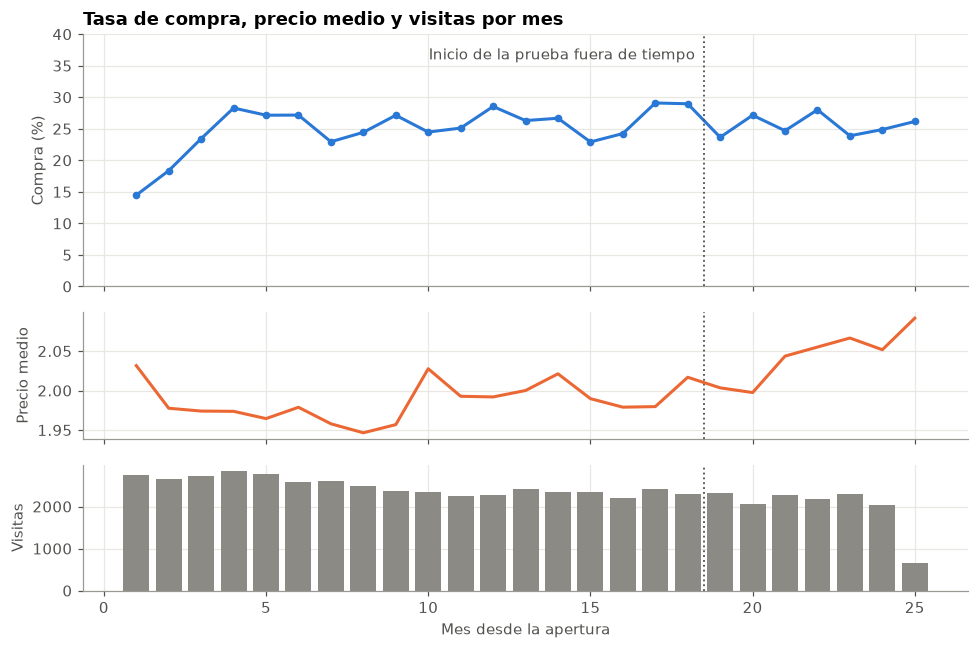

In [20]:
df['mes'] = (df['dia_visita'] - 1) // 30 + 1
por_mes = df.groupby('mes').agg(visitas=('incidencia_compra', 'size'), tasa=('incidencia_compra', 'mean'),
                                precio=('precio_medio', 'mean'))
fig, (arriba, medio, abajo) = plt.subplots(3, 1, figsize=(9, 6), sharex=True, height_ratios=[2, 1, 1])
arriba.plot(por_mes.index, por_mes['tasa'] * 100, color=AZUL, marker='o', markersize=4)
mes_oot = (INICIO_OOT - 1) // 30 + 1
for eje in (arriba, medio, abajo):
    eje.axvline(mes_oot - 0.5, color=TINTA, linestyle=':', linewidth=1.2)
arriba.annotate('Inicio de la prueba fuera de tiempo', (mes_oot - 0.5, 36), xytext=(-6, 0),
                textcoords='offset points', ha='right', color=TINTA)
arriba.set(ylabel='Compra (%)', ylim=(0, 40), title='Tasa de compra, precio medio y visitas por mes')
medio.plot(por_mes.index, por_mes['precio'], color=NARANJA)
medio.set_ylabel('Precio medio')
abajo.bar(por_mes.index, por_mes['visitas'], color=GRIS)
abajo.set(ylabel='Visitas', xlabel='Mes desde la apertura')
plt.tight_layout(); fig.savefig('img/tasa_compra_mensual.png', dpi=130, bbox_inches='tight'); plt.show()

**Lectura.**

- **Arranque.** La tasa empieza en 14.5 % el primer mes y llega a 28 % en el cuarto. Al abrir la tienda, todos los clientes son nuevos, y un cliente nuevo compra menos, como se vio en la sección 3.2.
- **Estabilidad.** Desde el mes 4, la tasa se mueve entre 23 % y 29 %, sin tendencia. No hay un quiebre que obligue a descartar el pasado.
- **Precio.** El precio medio oscila entre 1.95 y 2.03 en desarrollo y sube hasta 2.09 en la prueba OOT. Aun así, la tasa no cae, algo que la sección 13 examina.
- **Volumen.** Las visitas bajan levemente, de unas 2,700 a unas 2,200 por mes. El último mes tiene solo 7 días.

In [21]:
dias = df.drop_duplicates('dia_visita')
compras = df[df['incidencia_compra'] == 1]
marcas = pd.DataFrame([{
    'Marca': m,
    'Precio medio': dias[f'precio_marca_{m}'].mean(),
    'Mínimo': dias[f'precio_marca_{m}'].min(),
    'Máximo': dias[f'precio_marca_{m}'].max(),
    '% días en promoción': pct(dias[f'promo_marca_{m}'].mean()),
    'Precio en promoción vs sin promoción': pct(dias.groupby(f'promo_marca_{m}')[f'precio_marca_{m}'].mean().pipe(lambda s: s[1] / s[0] - 1)),
    'Participación en compras': pct((compras['id_marca'] == m).mean()),
    'Unidades por compra': compras.loc[compras['id_marca'] == m, 'cantidad'].mean(),
} for m in MARCAS]).set_index('Marca').round(2)
marcas

,Precio medio,Mínimo,Máximo,% días en promoción,Precio en promoción vs sin promoción,Participación en compras,Unidades por compra
Marca,,,,,,,
1,1.39,1.10,1.59,32.3 %,-6.2 %,9.2 %,3.49
2,1.78,1.26,1.90,30.5 %,-8.8 %,31.0 %,2.82
3,2.01,1.87,2.14,4.0 %,-1.0 %,5.7 %,3.56
4,2.16,1.76,2.26,11.0 %,-5.9 %,20.0 %,3.03
5,2.66,2.11,2.80,3.3 %,-5.2 %,34.0 %,2.25


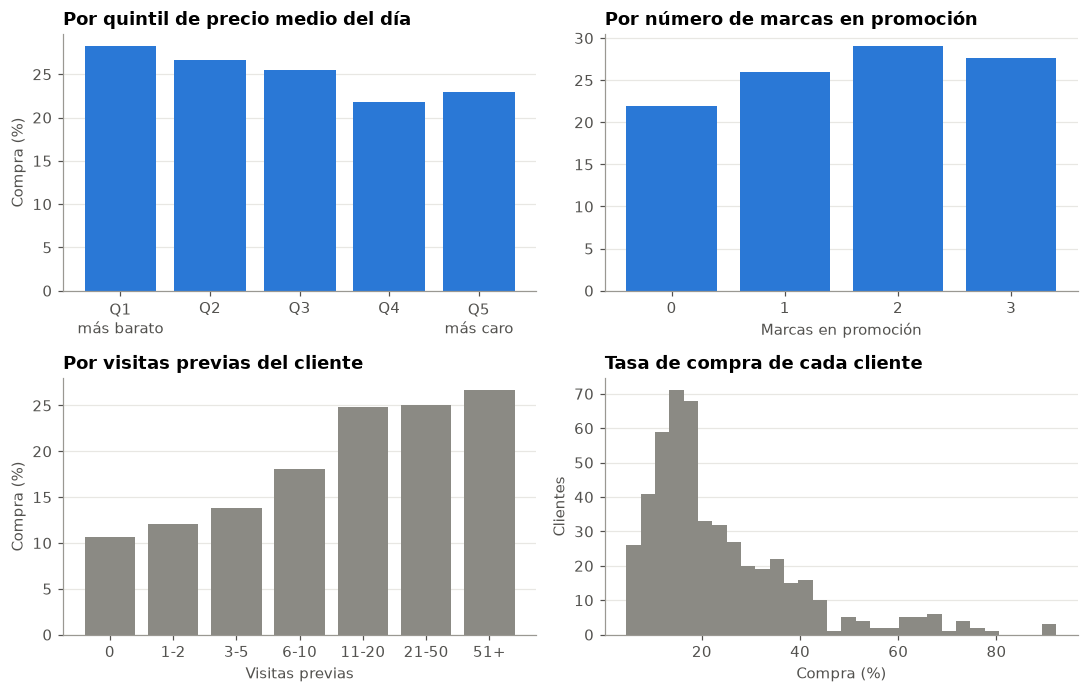

Correlación de la tasa de cada cliente entre el año 1 y el año 2: 0.76
El 10 % de clientes que más compra concentra 32.1 % de las compras
Tasa según la visita anterior: con compra 41.0 % | sin compra 19.7 %


In [22]:
fig, ejes = plt.subplots(2, 2, figsize=(10, 6.4))
q_precio = pd.qcut(df['precio_medio'], 5, labels=['Q1\nmás barato', 'Q2', 'Q3', 'Q4', 'Q5\nmás caro'])
t = df.groupby(q_precio, observed=True)['incidencia_compra'].mean() * 100
ejes[0, 0].bar(t.index.astype(str), t, color=AZUL); ejes[0, 0].set(title='Por quintil de precio medio del día', ylabel='Compra (%)')
t = df.groupby('n_promos')['incidencia_compra'].mean() * 100
ejes[0, 1].bar(t.index.astype(str), t, color=AZUL); ejes[0, 1].set(title='Por número de marcas en promoción', xlabel='Marcas en promoción')
tramos = pd.cut(df['n_visitas_previas'], [-1, 0, 2, 5, 10, 20, 50, 400], labels=['0', '1-2', '3-5', '6-10', '11-20', '21-50', '51+'])
t = df.groupby(tramos, observed=True)['incidencia_compra'].mean() * 100
ejes[1, 0].bar(t.index.astype(str), t, color=GRIS); ejes[1, 0].set(title='Por visitas previas del cliente', ylabel='Compra (%)', xlabel='Visitas previas')
tasa_cliente = df.groupby('id')['incidencia_compra'].mean()
ejes[1, 1].hist(tasa_cliente * 100, bins=30, color=GRIS); ejes[1, 1].set(title='Tasa de compra de cada cliente', xlabel='Compra (%)', ylabel='Clientes')
for e in ejes.flat:
    e.grid(axis='x', visible=False)
plt.tight_layout(); fig.savefig('img/eda_patrones.png', dpi=130, bbox_inches='tight'); plt.show()

anio1 = df[df['dia_visita'] <= 365].groupby('id')['incidencia_compra'].mean()
anio2 = df[df['dia_visita'] > 365].groupby('id')['incidencia_compra'].mean()
orden = df.groupby('id')['incidencia_compra'].sum().sort_values(ascending=False)
print(f'Correlación de la tasa de cada cliente entre el año 1 y el año 2: {anio1.corr(anio2):.2f}')
print(f'El 10 % de clientes que más compra concentra {pct(orden.head(len(orden) // 10).sum() / orden.sum())} de las compras')
print(f'Tasa según la visita anterior: con compra {pct(df.loc[df["compro_visita_anterior"] == 1, "incidencia_compra"].mean())} | '
      f'sin compra {pct(df.loc[df["compro_visita_anterior"] == 0, "incidencia_compra"].mean())}')

**Lectura.**

- **Marcas.** La marca 5, la más cara, es la más comprada (34.0 % de las compras), seguida de la marca 2 (31.0 %). Las marcas 1 y 2 están en promoción en cerca de un tercio de los días, con precios 6 % a 9 % más bajos. Las marcas 3 y 5 casi nunca lo están.
- **Precio y promociones.** La compra baja de cerca de 28 % en el quintil más barato a cerca de 22 % en los dos más caros, y sube con el número de marcas en promoción. Es la primera señal de que el precio importa.
- **Historia.** Es la señal más fuerte. Las primeras visitas de un cliente casi nunca terminan en compra, y la tasa se estabiliza después de unas 10 visitas. Tras una visita con compra, la tasa es 41.0 %, frente a 19.7 % tras una sin compra.
- **Clientes distintos y persistentes.** La tasa de cada cliente va de menos de 5 % a más de 90 %. Su correlación entre el primer y el segundo año es 0.76, y el 10 % de clientes que más compra concentra 32.1 % de las compras. Quien compraba mucho sigue comprando mucho, y por eso la tasa histórica es una regla difícil de superar.

Estos patrones anticipan dos resultados del análisis. La selección de variables (capítulo 7) confirmará que la historia del cliente es la información más útil para predecir la compra, y la tasa histórica será la regla simple que cualquier modelo debe superar (capítulo 8).

In [23]:
cliente = df.groupby('id').agg(**{v: (v, 'first') for v in DEMO}, tasa=('incidencia_compra', 'mean'))
cliente['edad_tramo'] = pd.cut(cliente['edad'], [0, 29, 44, 59, 100], labels=['18-29', '30-44', '45-59', '60+'])
cliente['ingreso_quintil'] = pd.qcut(cliente['ingreso_anual'], 5, labels=['Q1', 'Q2', 'Q3', 'Q4', 'Q5'])
visitas_cliente = df.groupby('id').size()
filas = []
for v in ['genero', 'estado_civil', 'nivel_educacion', 'ocupacion', 'edad_tramo', 'ingreso_quintil']:
    for grupo, sub in cliente.groupby(v, observed=True):
        w = visitas_cliente.loc[sub.index]
        filas.append({'Variable': v, 'Grupo': grupo, 'Clientes': len(sub), 'Tasa de compra': pct((sub['tasa'] * w).sum() / w.sum())})
pd.DataFrame(filas).set_index(['Variable', 'Grupo']).T

Variable        genero         estado_civil         nivel_educacion                         ocupacion                 edad_tramo                         ingreso_quintil                          \
Grupo                0       1            0       1               0       1       2       3         0       1       2      18-29   30-44   45-59     60+              Q1      Q2      Q3      Q4   
Clientes           306     194          304     196              75     314      99      12       184     248      68        129     228     100      43             100     100     100     100   
Tasa de compra  26.2 %  23.2 %       25.3 %  24.5 %          20.9 %  24.7 %  29.8 %  18.1 %    20.2 %  28.2 %  25.6 %     20.0 %  25.4 %  29.0 %  28.1 %          20.1 %  23.4 %  24.1 %  25.6 %   

Variable                
Grupo               Q5  
Clientes           100  
Tasa de compra  31.5 %

**Lectura.** Las diferencias por perfil existen, pero son menores que las de historia. La tasa sube con el ingreso (de 20.1 % en el quintil más bajo a 31.5 % en el más alto) y con la edad (de 20.0 % entre 18 y 29 años a 29.0 % entre 45 y 59). La ocupación 0 compra menos (20.2 %). El nivel de educación 3 tiene solo 12 clientes, así que su tasa no es confiable. El diccionario no explica qué significan los códigos de género, estado civil, educación y ocupación, así que los describimos por su número.

## 6. Segmentación de clientes

Agrupamos a los clientes con K-Means sobre sus seis variables demográficas, estandarizadas para que el ingreso no domine por su escala. La segmentación no usa la compra, así que no filtra información del resultado.

**Cómo se elige el número de segmentos.** Medimos dos cosas para cada `k`:

- **Silueta:** qué tan separados están los grupos. Va de −1 a 1, y más alto es mejor.
- **Estabilidad (ARI):** volvemos a agrupar 10 muestras bootstrap de clientes y comparamos las asignaciones con las originales. Un ARI de 1 indica que los grupos se reproducen exactamente.

Elegimos el `k` más estable. Un segmento que cambia con la muestra no sirve para diseñar acciones comerciales.

In [24]:
# Se evalúan de 2 a 8 segmentos. El máximo es 8 porque, con 500 clientes, más segmentos
# dejan grupos de menos de 30 clientes (6 %), demasiado pequeños para diseñar una acción comercial.
# La tabla siguiente lo confirma en la columna "Segmento más pequeño".
K_CANDIDATOS = range(2, 9)

In [25]:
clientes = df.groupby('id')[DEMO].first()
Z = StandardScaler().fit_transform(clientes)
rng = np.random.default_rng(SEMILLA)
filas = []
for k in K_CANDIDATOS:
    km = KMeans(k, n_init=20, random_state=SEMILLA).fit(Z)
    aris = []
    for b in range(10):
        idx = rng.integers(0, len(Z), len(Z))
        aris.append(adjusted_rand_score(km.labels_, KMeans(k, n_init=10, random_state=b).fit(Z[idx]).predict(Z)))
    filas.append({'k': k, 'Inercia': round(km.inertia_), 'Silueta': silhouette_score(Z, km.labels_),
                  'Estabilidad (ARI)': np.mean(aris), 'Segmento más pequeño': int(np.bincount(km.labels_).min())})
tabla_k = pd.DataFrame(filas).set_index('k')
K = int(tabla_k['Estabilidad (ARI)'].idxmax())
print(f'k elegido por estabilidad: {K}')
tabla_k.round(3)

k elegido por estabilidad: 3


,Inercia,Silueta,Estabilidad (ARI),Segmento más pequeño
k,,,,
2,2249,0.255,0.812,169
3,1775,0.270,0.839,107
4,1525,0.259,0.739,95
5,1340,0.279,0.726,38
6,1185,0.316,0.738,50
7,1062,0.314,0.688,27
8,953,0.344,0.795,29


In [26]:
km = KMeans(K, n_init=20, random_state=SEMILLA).fit(Z)
# Se numeran los segmentos de menor a mayor ingreso para que el orden no dependa del azar
orden_ingreso = clientes.groupby(km.labels_)['ingreso_anual'].mean().sort_values().index
clientes['segmento'] = pd.Series(km.labels_, index=clientes.index).map({s: i for i, s in enumerate(orden_ingreso)})
df['segmento'] = df['id'].map(clientes['segmento'])

perfil = clientes.groupby('segmento').agg(
    Clientes=('edad', 'size'), Edad=('edad', 'mean'), Ingreso=('ingreso_anual', 'mean'), **{'% género 1': ('genero', 'mean')},
    **{'% estado civil 1': ('estado_civil', 'mean')}, Educación=('nivel_educacion', 'mean'), Ocupación=('ocupacion', 'mean'))
perfil['Tasa de compra'] = df.groupby('segmento')['incidencia_compra'].mean()
perfil['Unidades por compra'] = df[df['incidencia_compra'] == 1].groupby('segmento')['cantidad'].mean()
NOMBRES = {0: 'Jóvenes de menor ingreso', 1: 'Adultos de ingreso medio', 2: 'Mayores de mayor ingreso'}
perfil.index = [NOMBRES.get(s, f'S{s}') for s in perfil.index]
perfil.assign(**{c: perfil[c].map(pct) for c in ['% género 1', '% estado civil 1', 'Tasa de compra']}).round(2)

,Clientes,Edad,Ingreso,% género 1,% estado civil 1,Educación,Ocupación,Tasa de compra,Unidades por compra
Jóvenes de menor ingreso,187,31.62,102405.11,79.7 %,66.3 %,1.01,0.53,21.2 %,2.98
Adultos de ingreso medio,206,36.83,118958.47,0.0 %,1.5 %,0.69,0.75,26.5 %,2.49
Mayores de mayor ingreso,107,54.56,159858.70,42.1 %,64.5 %,2.04,1.21,28.8 %,3.01


**Lectura.** Con `k = 3`, la segmentación es la más estable (ARI de 0.839) y el segmento más pequeño tiene 107 clientes. La silueta es baja en todos los casos (0.25 a 0.34): los grupos se solapan, como suele ocurrir con datos demográficos. Los segmentos son un **resumen útil**, no grupos naturales bien separados.

| Segmento | Clientes | Perfil | Tasa de compra |
|---|---|---|---|
| **Jóvenes de menor ingreso** | 187 | 32 años, ingreso de 102 mil, 80 % con género 1 | 21.2 % |
| **Adultos de ingreso medio** | 206 | 37 años, ingreso de 119 mil, todos con género 0 y casi todos con estado civil 0 | 26.5 % |
| **Mayores de mayor ingreso** | 107 | 55 años, ingreso de 160 mil, mayor nivel de educación | 28.8 % |

Los adultos de ingreso medio compran menos unidades por compra (2.49, frente a 3.0 en los otros dos). La sección 13 mostrará que la diferencia más importante entre segmentos no está en la tasa sino en su respuesta al precio.

## 7. Selección de variables

Una variable entra al modelo solo si varía lo suficiente, se mantiene estable en el tiempo, separa a quienes compran, tiene el sentido esperado y no repite lo que ya dicen otras. Todas las medidas se calculan con los datos de desarrollo (días 1 a 547). La prueba OOT no participa.

Los filtros se aplican en este orden, y cada uno evalúa solo las variables que pasaron el anterior:

| Paso | Prueba | Se descarta si | Pregunta que responde |
|---|---|---|---|
| 1 | Inventario y criterio experto | Fuga de información o indicación del negocio | ¿Se conoce antes de que el cliente decida? |
| 2 | Concentración | Un valor reúne más de 95 % de las visitas | ¿La variable casi no varía? |
| 3 | Population Stability Index (PSI) | > 0.25 en algún bloque | ¿Su distribución cambió demasiado? |
| 4 | Information Value (IV) y Gini por bloque | IV mínimo ≤ 0.02, Gini mínimo ≤ 0.03 o coeficiente de variación del Gini ≥ 0.80 | ¿Separa de forma consistente a quienes compran? |
| 5 | Sentido | El signo observado contradice el esperado | ¿Su efecto tiene lógica de negocio? |
| 6 | Correlación de Spearman y VIF | Correlación > 0.85 con una variable de mayor Gini | ¿Repite la información de otra variable? |

**Concentración de 95 %.** El umbral es más alto que el habitual en riesgo de crédito (85 %), porque aquí hay indicadores de eventos poco frecuentes, como la promoción de una marca, que pueden ser informativos.

**Correlación de 0.85.** Es el umbral para aprendizaje automático. La logística del campeón usa todas las candidatas, con penalización L2, como contraste.

In [27]:
# Selección de variables
DIAS_ARRANQUE, N_GRUPOS = 91, 10
MAX_CONCENTRACION = 0.95
PSI_REVISAR, PSI_EXCLUIR = 0.10, 0.25
MIN_IV, MIN_GINI, MAX_CV_GINI = 0.02, 0.03, 0.80
MAX_CORRELACION = 0.85

### 7.1 Inventario de candidatas

Las candidatas son las 30 variables de la sección 4. Cada una tiene un **sentido esperado**: si al subir la variable debería subir o bajar la probabilidad de compra. Las variables del perfil del cliente y las categóricas no tienen hipótesis previa.

**Exclusión por criterio experto**, antes de medir nada: `id_marca` y `cantidad` son el resultado de la visita, `tamanio_ciudad` se excluye por indicación del diccionario e `id` es un identificador.

In [28]:
SUBE, BAJA, SIN_HIPOTESIS = 'sube la compra', 'baja la compra', 'sin hipótesis'
SENTIDO = {'tasa_historica': SUBE, 'compro_visita_anterior': SUBE, 'n_visitas_previas': SUBE, 'dias_desde_compra': BAJA,
           'sin_compras_previas': BAJA, 'unidades_por_compra': SUBE, 'precio_medio': BAJA, 'n_promos': SUBE,
           'precio_preferida': BAJA, 'promo_preferida': SUBE}
SENTIDO |= {v: BAJA for v in PRECIOS} | {v: SUBE for v in PROMOS}
CANDIDATAS = HISTORIA + PRECIO + CLIENTE
EXCLUSION_EXPERTA = {'id_marca': 'Resultado de la visita: fuga de información',
                     'cantidad': 'Resultado de la visita: fuga de información',
                     'tamanio_ciudad': 'El diccionario indica no considerarla', 'id': 'Identificador del cliente'}
grupo_de = {**{v: 'historia' for v in HISTORIA}, **{v: 'precio' for v in PRECIO}, **{v: 'cliente' for v in CLIENTE}}
inventario = pd.DataFrame({'grupo': [grupo_de[c] for c in CANDIDATAS],
                           'sentido esperado': [SENTIDO.get(c, SIN_HIPOTESIS) for c in CANDIDATAS]}, index=CANDIDATAS)
en_dev = mascara_train(INICIO_OOT)
X_dev = df.loc[en_dev, CANDIDATAS].astype(float)
print(f'{len(CANDIDATAS)} candidatas | {len(EXCLUSION_EXPERTA)} columnas retiradas por criterio experto | '
      f'{int(y[en_dev].sum()):,} compras en desarrollo')
display(pd.Series(EXCLUSION_EXPERTA, name='Motivo').to_frame())
inventario.T

30 candidatas | 4 columnas retiradas por criterio experto | 11,283 compras en desarrollo


,Motivo
id_marca,Resultado de la visita: fuga de información
cantidad,Resultado de la visita: fuga de información
tamanio_ciudad,El diccionario indica no considerarla
id,Identificador del cliente


,tasa_historica,compro_visita_anterior,n_visitas_previas,dias_desde_visita,dias_desde_compra,sin_compras_previas,unidades_por_compra,ultima_marca_comprada,marca_preferida,precio_marca_1,precio_marca_2,precio_marca_3,precio_marca_4,precio_marca_5,promo_marca_1,promo_marca_2,promo_marca_3,promo_marca_4,promo_marca_5,precio_medio,n_promos,precio_preferida,promo_preferida,genero,estado_civil,edad,nivel_educacion,ingreso_anual,ocupacion,segmento
grupo,historia,historia,historia,historia,historia,historia,historia,historia,historia,precio,precio,precio,precio,precio,precio,precio,precio,precio,precio,precio,precio,precio,precio,cliente,cliente,cliente,cliente,cliente,cliente,cliente
sentido esperado,sube la compra,sube la compra,sube la compra,sin hipótesis,baja la compra,baja la compra,sube la compra,sin hipótesis,sin hipótesis,baja la compra,baja la compra,baja la compra,baja la compra,baja la compra,sube la compra,sube la compra,sube la compra,sube la compra,sube la compra,baja la compra,sube la compra,baja la compra,sube la compra,sin hipótesis,sin hipótesis,sin hipótesis,sin hipótesis,sin hipótesis,sin hipótesis,sin hipótesis


### 7.2 Filtro univariado

Una variable que casi no cambia entre visitas no puede separarlas. Medimos la **concentración**: la proporción de visitas en el valor más frecuente. No hay faltantes, así que ese criterio no aplica.

In [29]:
univariado = pd.DataFrame({'concentración': X_dev.apply(lambda x: x.value_counts(normalize=True).iloc[0]),
                           'desv. estándar': X_dev.std()})
univariado['falla'] = np.select([univariado['desv. estándar'] == 0, univariado['concentración'] > MAX_CONCENTRACION],
                                ['sin variación', 'concentración'], '')
pasan_univariado = univariado.index[univariado['falla'] == ''].tolist()
print(f'Pasan el filtro univariado: {len(pasan_univariado)} de {len(CANDIDATAS)}')
univariado.sort_values('concentración', ascending=False).head(8).round(3)

Pasan el filtro univariado: 28 de 30


,concentración,desv. estándar,falla
promo_marca_3,0.971,0.169,concentración
promo_marca_5,0.953,0.211,concentración
sin_compras_previas,0.889,0.314,
promo_marca_4,0.856,0.352,
promo_preferida,0.811,0.392,
compro_visita_anterior,0.754,0.431,
ultima_marca_comprada,0.754,1.650,
promo_marca_2,0.688,0.463,


**Lectura.** Pasan 28 de 30. Salen `promo_marca_3` (97.1 % de las visitas sin promoción) y `promo_marca_5` (95.3 %): esas marcas casi nunca están en promoción. `sin_compras_previas` pasa por poco (88.9 %), y la prueba de estabilidad la evaluará.

### 7.3 Estabilidad en el tiempo (PSI)

El PSI compara la proporción de visitas por grupo entre una distribución de referencia ($p$) y otra a evaluar ($q$):

$$PSI = \sum_{\text{grupos}} (p - q)\,\ln\frac{p}{q}$$

- **Referencia:** los días 92 a 273. Se excluye el primer trimestre (`DIAS_ARRANQUE`), porque con la tienda recién abierta todos los clientes son nuevos y las variables de historia aún no se forman.
- **Evaluación:** cada uno de los tres bloques de desarrollo. Se conserva el PSI máximo.
- **Grupos:** deciles de la referencia, o un grupo por valor si la variable tiene 12 valores o menos.
- **Lectura:** hasta 0.10 es estable, entre 0.10 y 0.25 avanza con vigilancia, y más de 0.25 se excluye.

In [30]:
def cortes_fijos(x, n=N_GRUPOS):
    """Un grupo por valor si hay pocos valores distintos; deciles en otro caso."""
    valores = np.unique(x)
    return valores[1:] if len(valores) <= 12 else np.unique(np.quantile(x, np.linspace(0, 1, n + 1)[1:-1]))

def asignar_grupo(x, cortes):
    return np.searchsorted(cortes, x, side='right')

def psi(referencia, evaluacion, eps=1e-4):
    cortes = cortes_fijos(referencia)
    k = len(cortes) + 1
    p = np.clip(np.bincount(asignar_grupo(referencia, cortes), minlength=k) / len(referencia), eps, None)
    q = np.clip(np.bincount(asignar_grupo(evaluacion, cortes), minlength=k) / len(evaluacion), eps, None)
    return float(np.sum((p - q) * np.log(p / q)))

en_ref = ((df['dia_visita'] > DIAS_ARRANQUE) & (df['dia_visita'] < BLOQUES_MODELAMIENTO[0][0])).to_numpy()
estabilidad = pd.DataFrame({f'Días {d} a {h}': {c: psi(df.loc[en_ref, c].to_numpy(float), df.loc[mascara(d, h), c].to_numpy(float))
                                              for c in pasan_univariado} for d, h in BLOQUES_MODELAMIENTO})
estabilidad['PSI máximo'] = estabilidad.max(axis=1)
estabilidad['lectura'] = np.select([estabilidad['PSI máximo'] > PSI_EXCLUIR, estabilidad['PSI máximo'] > PSI_REVISAR],
                                   ['excluir', 'revisar'], 'estable')
pasan_estabilidad = estabilidad.index[estabilidad['lectura'] != 'excluir'].tolist()
print(f'Pasan la prueba de estabilidad: {len(pasan_estabilidad)} de {len(pasan_univariado)}')
estabilidad.sort_values('PSI máximo', ascending=False).round(3)

Pasan la prueba de estabilidad: 14 de 28


,Días 274 a 365,Días 366 a 456,Días 457 a 547,PSI máximo,lectura
precio_marca_3,7.494,10.512,6.772,10.512,excluir
n_visitas_previas,4.543,6.999,7.999,7.999,excluir
precio_marca_2,5.205,4.176,3.184,5.205,excluir
precio_medio,2.834,1.357,2.420,2.834,excluir
precio_marca_4,2.158,1.167,2.437,2.437,excluir
precio_marca_5,1.369,2.150,0.320,2.150,excluir
precio_marca_1,0.760,1.691,1.307,1.691,excluir
precio_preferida,0.442,1.047,1.035,1.047,excluir
promo_marca_1,0.271,0.678,0.026,0.678,excluir
n_promos,0.650,0.453,0.243,0.650,excluir


**Lectura.** Pasan 14 de 28, y la exclusión revela tres problemas distintos:

- **Las 10 variables de precio que llegan a esta etapa son inestables** (PSI de 0.65 a 10.5). El nivel de precios cambia por épocas, así que una variable de precio del día describe el calendario más que al cliente. Un modelo que las use aprende niveles de precio que no tienen por qué repetirse. El efecto del precio se estima aparte, en la sección 13.
- **`n_visitas_previas` es inestable por construcción** (PSI de 8.0). Crece con la antigüedad de la tienda, así que en la prueba OOT todos los clientes tienen más visitas que nunca en el entrenamiento.
- **Tres variables de historia se forman lentamente:** `marca_preferida` (0.27), `unidades_por_compra` (0.32) y `sin_compras_previas` (0.26). Su distribución sigue cambiando a medida que los clientes acumulan compras.

`tasa_historica` avanza con vigilancia (0.102). Las variables del perfil tienen PSI cero, porque son siempre los mismos clientes.

### 7.4 Relación con la compra (IV, Gini y sentido)

Para cada candidata y cada bloque de desarrollo:

1. Con los días anteriores al bloque se fijan los grupos y se calcula el **peso de evidencia** de cada grupo: $WoE = \ln\left(\frac{\%\ \text{de las compras}}{\%\ \text{de las visitas sin compra}}\right)$. Un WoE positivo indica un grupo que compra más que el promedio. Se suma 0.5 a cada conteo para evitar logaritmos infinitos.
2. En el bloque se mide el **Gini** del WoE usado como score y el **valor de información**: $IV = \sum (\%\ \text{compras} - \%\ \text{sin compra}) \times WoE$.

Así, cada medida sale de días que no se usaron para fijar los grupos, igual que en la comparación de modelos. El **sentido observado** es el signo de la correlación de Spearman con la compra en desarrollo.

In [31]:
def woe_iv(grupo, y_r, k, suavizado=0.5):
    compras_g = np.bincount(grupo, weights=y_r, minlength=k)
    sin_compra_g = np.bincount(grupo, minlength=k) - compras_g
    p_si = (compras_g + suavizado) / (compras_g.sum() + suavizado * k)
    p_no = (sin_compra_g + suavizado) / (sin_compra_g.sum() + suavizado * k)
    woe = np.log(p_si / p_no)
    return woe, float(np.sum((p_si - p_no) * woe))

def bivariado(c):
    x = df[c].to_numpy(float)
    ginis, ivs = [], []
    for d, h in BLOQUES_MODELAMIENTO:
        tr, te = mascara_train(d), mascara(d, h)
        cortes = cortes_fijos(x[tr])
        k = len(cortes) + 1
        woe, _ = woe_iv(asignar_grupo(x[tr], cortes), y[tr], k)
        g_te = asignar_grupo(x[te], cortes)
        ginis.append(gini(y[te], woe[g_te]))
        ivs.append(woe_iv(g_te, y[te], k)[1])
    ginis = np.array(ginis)
    return pd.Series({'IV mínimo': min(ivs), 'Gini medio': ginis.mean(), 'Gini mínimo': ginis.min(),
                      'CV del Gini': ginis.std() / abs(ginis.mean()) if ginis.mean() != 0 else np.inf})

relacion = pd.DataFrame({c: bivariado(c) for c in pasan_estabilidad}).T
compra_dev = pd.Series(y[en_dev], index=X_dev.index)
relacion['sentido observado'] = [SUBE if X_dev[c].corr(compra_dev, method='spearman') > 0 else BAJA for c in pasan_estabilidad]
relacion['sentido esperado'] = inventario['sentido esperado']
relacion['falla'] = [', '.join(regla for regla, falla in [
        ('IV', r['IV mínimo'] <= MIN_IV), ('Gini', r['Gini mínimo'] <= MIN_GINI), ('CV del Gini', r['CV del Gini'] >= MAX_CV_GINI),
        ('sentido', r['sentido esperado'] != SIN_HIPOTESIS and r['sentido esperado'] != r['sentido observado'])] if falla)
    for _, r in relacion.iterrows()]
pasan_bivariado = relacion.index[relacion['falla'] == ''].tolist()
print(f'Pasan la prueba de relación con la compra: {len(pasan_bivariado)} de {len(pasan_estabilidad)}')
relacion.sort_values('Gini medio', ascending=False).round(3)

Pasan la prueba de relación con la compra: 9 de 14


,IV mínimo,Gini medio,Gini mínimo,CV del Gini,sentido observado,sentido esperado,falla
tasa_historica,0.706,0.444,0.413,0.053,sube la compra,sube la compra,
dias_desde_compra,0.335,0.359,0.312,0.110,baja la compra,baja la compra,
ultima_marca_comprada,0.305,0.245,0.215,0.124,sube la compra,sin hipótesis,
compro_visita_anterior,0.171,0.219,0.190,0.143,sube la compra,sube la compra,
dias_desde_visita,0.072,0.169,0.126,0.188,baja la compra,sin hipótesis,
edad,0.043,0.151,0.114,0.175,sube la compra,sin hipótesis,
ingreso_anual,0.053,0.125,0.106,0.115,sube la compra,sin hipótesis,
ocupacion,0.034,0.110,0.095,0.097,sube la compra,sin hipótesis,
segmento,0.028,0.099,0.085,0.167,sube la compra,sin hipótesis,
nivel_educacion,0.012,0.093,0.055,0.293,sube la compra,sin hipótesis,IV


**Lectura.** Pasan 9 de 14.

- **La historia es la que más separa.** `tasa_historica` tiene un Gini medio de 0.444 y un IV mínimo de 0.706. Le siguen los días desde la última compra (0.359) y la marca de la visita anterior (0.245).
- **El perfil aporta poco, pero de forma consistente.** Edad, ingreso, ocupación y segmento tienen Gini de 0.10 a 0.15.
- **Salen cinco variables por falta de relación:** `nivel_educacion` (IV de 0.012), `promo_marca_2`, `promo_preferida`, `genero` y `estado_civil`.
- **Ninguna variable con hipótesis contradice su sentido esperado.** Más días desde la última compra se asocian a menos compra, y una mayor tasa histórica a más compra.

### 7.5 Correlación

Dos variables que miden casi lo mismo no aportan información nueva, y reparten la importancia entre ellas. Usamos la correlación de Spearman, que capta relaciones monótonas aunque no sean lineales.

**Regla:** se ordenan las variables por Gini medio y se recorren en ese orden. Una variable entra solo si su correlación con todas las ya elegidas es menor o igual a 0.85. **Entre dos variables correlacionadas siempre se queda la de mayor Gini.**

El **VIF** mide cuánto de una variable se explica con las demás en conjunto: hasta 5 es aceptable, entre 5 y 10 hay que revisar, y más de 10 se excluye o se transforma.

In [32]:
correlacion = X_dev[pasan_bivariado].corr(method='spearman').abs()
orden = relacion.loc[pasan_bivariado].sort_values(['Gini medio', 'CV del Gini'], ascending=[False, True], kind='stable').index
SELECCIONADAS, redundantes = [], {}
for c in orden:
    choque = [e for e in SELECCIONADAS if correlacion.loc[c, e] > MAX_CORRELACION]
    if choque:
        redundantes[c] = {'Gini': relacion.loc[c, 'Gini medio'], 'redundante con': choque[0],
                          'Gini de la elegida': relacion.loc[choque[0], 'Gini medio'], 'correlación': correlacion.loc[c, choque[0]]}
    else:
        SELECCIONADAS.append(c)
assert all(r['Gini de la elegida'] >= r['Gini'] for r in redundantes.values()), 'Se excluyó una variable con más Gini'

final = correlacion.loc[SELECCIONADAS, SELECCIONADAS].mask(np.eye(len(SELECCIONADAS), dtype=bool), 0)
vif = pd.Series(np.diag(np.linalg.inv(X_dev[SELECCIONADAS].corr().to_numpy())), index=SELECCIONADAS)
print(f'{len(pasan_bivariado)} variables llegan a esta etapa y quedan {len(SELECCIONADAS)} | '
      f'correlación máxima entre las elegidas: {final.max().max():.3f} | VIF máximo: {vif.max():.2f}')
display(pd.DataFrame(redundantes).T.infer_objects().round(3))
vif.sort_values(ascending=False).round(2).to_frame('VIF').T

9 variables llegan a esta etapa y quedan 8 | correlación máxima entre las elegidas: 0.729 | VIF máximo: 2.43


,Gini,redundante con,Gini de la elegida,correlación
compro_visita_anterior,0.219,ultima_marca_comprada,0.245,0.988


,ingreso_anual,ocupacion,segmento,edad,tasa_historica,ultima_marca_comprada,dias_desde_compra,dias_desde_visita
VIF,2.43,2.1,2.07,1.87,1.58,1.49,1.38,1.01


### 7.6 Decisión por variable

La tabla resume el paso en el que salió cada candidata o la lectura con la que avanza. `SELECCIONADAS` es la lista que usan los modelos con el conjunto `seleccionado`.

In [33]:
def decision(c):
    if univariado.loc[c, 'falla']:
        return 'excluida', f"univariado: {univariado.loc[c, 'falla']}"
    if estabilidad.loc[c, 'lectura'] == 'excluir':
        return 'excluida', 'estabilidad: PSI > 0.25'
    if relacion.loc[c, 'falla']:
        return 'excluida', f"relación con la compra: {relacion.loc[c, 'falla']}"
    if c in redundantes:
        return 'excluida', f"correlación con {redundantes[c]['redundante con']}"
    if estabilidad.loc[c, 'lectura'] == 'revisar':
        return 'avanza', 'PSI entre 0.10 y 0.25: vigilar'
    return 'avanza', ''

decisiones = pd.concat([inventario['grupo'], univariado['concentración'], estabilidad['PSI máximo'],
                        relacion[['IV mínimo', 'Gini medio']]], axis=1).reindex(CANDIDATAS)
decisiones[['decisión', 'motivo']] = [decision(c) for c in CANDIDATAS]
display(decisiones.groupby(['decisión', 'grupo'])['motivo'].value_counts().to_frame('variables'))
print('Variables seleccionadas:', ', '.join(SELECCIONADAS))
decisiones.sort_values(['decisión', 'Gini medio'], ascending=[True, False]).round(3)

variables
decisión grupo    motivo                                                  
avanza   cliente                                                         4
         historia                                                        3
                  PSI entre 0.10 y 0.25: vigilar                         1
excluida cliente  relación con la compra: IV, Gini                       1
                  relación con la compra: IV, Gini, CV del Gini          1
                  relación con la compra: IV                             1
         historia estabilidad: PSI > 0.25                                4
                  correlación con ultima_marca_comprada                  1
         precio   estabilidad: PSI > 0.25                               10
                  univariado: concentración                              2
                  relación con la compra: IV, Gini                       1
                  relación con la compra: IV, Gini, CV del Gini          1

Variables seleccionadas: tasa_historica, dias_desde_compra, ultima_marca_comprada, dias_desde_visita, edad, ingreso_anual, ocupacion, segmento


,grupo,concentración,PSI máximo,IV mínimo,Gini medio,decisión,motivo
tasa_historica,historia,0.011,0.102,0.706,0.444,avanza,PSI entre 0.10 y 0.25: vigilar
dias_desde_compra,historia,0.162,0.029,0.335,0.359,avanza,
ultima_marca_comprada,historia,0.754,0.011,0.305,0.245,avanza,
dias_desde_visita,historia,0.211,0.093,0.072,0.169,avanza,
edad,cliente,0.049,0.000,0.043,0.151,avanza,
ingreso_anual,cliente,0.007,0.001,0.053,0.125,avanza,
ocupacion,cliente,0.510,0.000,0.034,0.110,avanza,
segmento,cliente,0.418,0.000,0.028,0.099,avanza,
compro_visita_anterior,historia,0.754,0.001,0.171,0.219,excluida,correlación con ultima_marca_comprada
nivel_educacion,cliente,0.633,0.001,0.012,0.093,excluida,relación con la compra: IV


**Lectura.** De 30 candidatas quedan 8: 4 de historia y 4 del perfil del cliente.

- **Solo una sale por correlación.** `compro_visita_anterior` tiene una correlación de 0.988 con `ultima_marca_comprada`, que la contiene: la marca 0 significa que no hubo compra.
- **No queda colinealidad.** La correlación más alta entre las elegidas es 0.729 y el VIF máximo es 2.43, muy por debajo de 5.
- **Ninguna variable de precio queda en el modelo de propensión.** El precio sirve para explicar **cuánto** se compra un día, pero no **quién** compra más. Las secciones 11 y 13 confirman esta separación.

## 8. Comparación de campeón, retadores y ajuste fino

Las 10 configuraciones cruzan estos elementos:

- **Algoritmos:** regla simple, regresión logística, LightGBM con sus valores por defecto y LightGBM con ajuste fino.
- **Conjuntos de variables:** `seleccionado` (las variables que pasaron la sección 7), `historia` (solo las seleccionadas de historia) y `completo` (las 30 candidatas, sin selección).
- **Regla simple:** ordenar por la tasa histórica de compra del cliente.
- **Campeón:** la regresión logística con todas las variables.

**Quiénes pueden ser elegidos.** Solo las configuraciones que respetan la selección de variables (`historia` y `seleccionado`) y la regla simple. Las configuraciones `completo`, incluido el campeón, se entrenan como referencia: usan 14 variables que la sección 7 descartó por inestables, y un modelo así no debería llegar a producción.

**Regla de decisión.** Medimos `robusto = media(Gini) − desviación(Gini)` en los tres bloques de desarrollo. Entre las configuraciones aptas a menos de 0.01 de la mejor, elegimos la más simple: primero por algoritmo y después por número de variables. Así se premia a los modelos buenos **y** estables, y se limita el sesgo de elegir entre muchas alternativas.

In [34]:
# Segmentación, ajuste fino y reproducibilidad
K_CANDIDATOS = range(2, 9)
N_ITER_TUNING = 20
SEMILLA, N_BOOTSTRAP, N_BOOT_DIAS = 42, 1000, 200

### 8.1. Qué modelos compiten

| Modelo | Idea principal | A favor | En contra |
|---|---|---|---|
| **Regla simple** | Ordenar por la tasa histórica del cliente | Fácil de explicar, sin entrenamiento | No reacciona al precio ni a la última visita |
| **Regresión logística** | Suma ponderada de variables convertida en probabilidad | Interpretable y estable | Capta menos relaciones no lineales |
| **LightGBM** | Árboles que corrigen los errores de los anteriores; crece cada árbol hoja por hoja | Muy potente en datos tabulares y rápido | Menos interpretable, y extrapola mal |
| **XGBoost** | La misma idea; crece cada árbol nivel por nivel, con regularización explícita | Muy potente en datos tabulares y estable | Menos interpretable, y sus valores por defecto generan árboles profundos |
| **Versiones ajustadas** | El mismo algoritmo con hiperparámetros elegidos por búsqueda aleatoria | Aprovechan mejor los datos | Pueden sobreajustarse a los bloques de desarrollo |

**Ajuste fino.** Para cada algoritmo probamos 20 combinaciones aleatorias de hiperparámetros con las variables seleccionadas y nos quedamos con la de mayor Gini medio en desarrollo. Los dos espacios de búsqueda son equivalentes: número y tamaño de los árboles, tasa de aprendizaje y regularización. La prueba OOT no participa en esta búsqueda.

In [35]:
# Espacios de búsqueda equivalentes: tamaño del árbol, número de árboles, aprendizaje y regularización
ESPACIO = dict(n_estimators=[200, 400, 800], learning_rate=[0.01, 0.03, 0.05], num_leaves=[7, 15, 31, 63],
               min_child_samples=[50, 100, 200, 400], colsample_bytree=[0.6, 0.8, 1.0], reg_lambda=[0, 1, 5, 20])
ESPACIO_XGB = dict(n_estimators=[200, 400, 800], learning_rate=[0.01, 0.03, 0.05], max_depth=[2, 3, 4, 6],
                   min_child_weight=[1, 5, 20, 50], colsample_bytree=[0.6, 0.8, 1.0], reg_lambda=[0, 1, 5, 20])
MEJORES_PARAMS, MEJORES_PARAMS_XGB = {}, {}

@dataclass
class Ajuste:
    variables: list
    modelo: object
    predecir: callable

def crear(algoritmo, variables, params=None):
    if algoritmo == 'logistica':
        num = [v for v in variables if v not in CATEGORICAS]
        cat = [v for v in variables if v in CATEGORICAS]
        prep = ColumnTransformer([('num', StandardScaler(), num),
                                  ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat)])
        return make_pipeline(prep, LogisticRegression(max_iter=5000))
    if algoritmo == 'lightgbm':
        return LGBMClassifier(random_state=SEMILLA, n_jobs=4, verbose=-1)
    if algoritmo == 'lightgbm_ajustado':
        params = params if params is not None else MEJORES_PARAMS
        return LGBMClassifier(subsample=0.8, subsample_freq=1, random_state=SEMILLA, n_jobs=4, verbose=-1, **params)
    if algoritmo == 'xgboost':
        return XGBClassifier(eval_metric='logloss', random_state=SEMILLA, n_jobs=4)
    params = params if params is not None else MEJORES_PARAMS_XGB
    return XGBClassifier(subsample=0.8, eval_metric='logloss', random_state=SEMILLA, n_jobs=4, **params)

def ajustar(algoritmo, variables, en_train, params=None):
    if algoritmo == 'regla':
        return Ajuste(['tasa_historica'], None, lambda d: d['tasa_historica'].to_numpy())
    variables = list(variables)
    m = crear(algoritmo, variables, params).fit(df.loc[en_train, variables], y[en_train])
    return Ajuste(variables, m, lambda d: m.predict_proba(d[variables])[:, 1])

def ginis_desarrollo(algoritmo, variables, params=None):
    return [gini(y[mascara(d, h)], ajustar(algoritmo, variables, mascara_train(d), params).predecir(df.loc[mascara(d, h)]))
            for d, h in BLOQUES_MODELAMIENTO]

In [36]:
def busqueda_aleatoria(algoritmo, espacio):
    """Prueba N_ITER_TUNING combinaciones al azar y devuelve la de mayor Gini medio en desarrollo."""
    rng = np.random.default_rng(SEMILLA)
    candidatos = [{k: v[int(rng.integers(len(v)))] for k, v in espacio.items()} for _ in range(N_ITER_TUNING)]
    filas = []
    for p in candidatos:
        gs = ginis_desarrollo(algoritmo, SELECCIONADAS, p)
        filas.append({**p, 'Gini medio': np.mean(gs), 'Desviación': np.std(gs, ddof=1)})
    tabla = pd.DataFrame(filas).sort_values('Gini medio', ascending=False)
    return candidatos[tabla.index[0]], tabla

MEJORES_PARAMS, busqueda = busqueda_aleatoria('lightgbm_ajustado', ESPACIO)
MEJORES_PARAMS_XGB, busqueda_xgb = busqueda_aleatoria('xgboost_ajustado', ESPACIO_XGB)
for nombre, defecto, mejores, tabla in [('LightGBM', 'lightgbm', MEJORES_PARAMS, busqueda),
                                         ('XGBoost', 'xgboost', MEJORES_PARAMS_XGB, busqueda_xgb)]:
    print(f'{nombre}: Gini medio con valores por defecto {np.mean(ginis_desarrollo(defecto, SELECCIONADAS)):.3f} | '
          f'ajustado {tabla["Gini medio"].iloc[0]:.3f} | mejores hiperparámetros {mejores}')
display(busqueda.head(5).round(3))
busqueda_xgb.head(5).round(3)

LightGBM: Gini medio con valores por defecto 0.472 | ajustado 0.486 | mejores hiperparámetros {'n_estimators': 400, 'learning_rate': 0.03, 'num_leaves': 7, 'min_child_samples': 50, 'colsample_bytree': 0.6, 'reg_lambda': 0}


XGBoost: Gini medio con valores por defecto 0.434 | ajustado 0.485 | mejores hiperparámetros {'n_estimators': 800, 'learning_rate': 0.03, 'max_depth': 2, 'min_child_weight': 50, 'colsample_bytree': 0.8, 'reg_lambda': 20}


,n_estimators,learning_rate,num_leaves,min_child_samples,colsample_bytree,reg_lambda,Gini medio,Desviación
19,400,0.03,7,50,0.6,0,0.486,0.024
1,200,0.05,7,50,0.8,20,0.486,0.025
5,400,0.01,7,200,1.0,0,0.485,0.026
14,400,0.05,7,100,1.0,20,0.482,0.025
7,800,0.03,7,400,0.8,20,0.481,0.025


,n_estimators,learning_rate,max_depth,min_child_weight,colsample_bytree,reg_lambda,Gini medio,Desviación
7,800,0.03,2,50,0.8,20,0.485,0.023
14,400,0.05,2,5,1.0,20,0.485,0.025
11,800,0.03,2,5,1.0,0,0.485,0.024
19,400,0.03,2,1,0.6,0,0.484,0.023
1,200,0.05,2,1,0.8,20,0.484,0.024


**Lectura.** El ajuste fino importa, sobre todo en XGBoost. Con las 8 variables seleccionadas, LightGBM pasa de 0.472 a 0.486 de Gini medio en desarrollo, y XGBoost de 0.434 a 0.485. Los valores por defecto de XGBoost generan árboles de 6 niveles, demasiado profundos para tan pocas variables, y se sobreajustan.

Los dos algoritmos coinciden en lo esencial: prefieren **árboles pequeños**. Las cinco mejores combinaciones de LightGBM usan 7 hojas, y las de XGBoost, 2 niveles de profundidad. En ambos casos, las cinco mejores quedan a menos de 0.005 entre sí: la superficie es plana, así que no conviene darle demasiada importancia a un valor exacto de los hiperparámetros.

In [37]:
# Parametros
CUPO = 0.20
DESCUENTO, MARGEN_BRUTO = 0.05, 0.30
TOLERANCIA_GINI = 0.01

In [38]:
CONJUNTOS = {'historia': [v for v in SELECCIONADAS if v in HISTORIA], 'seleccionado': SELECCIONADAS, 'completo': CANDIDATAS}
COMPLEJIDAD = dict(regla=0, logistica=1, lightgbm=2, xgboost=2, lightgbm_ajustado=3, xgboost_ajustado=3)
REGLA = ('regla', 'tasa histórica')
CAMPEON = ('logistica', 'completo')
CONFIGS = [REGLA] + [(a, s) for a in ['logistica', 'lightgbm', 'lightgbm_ajustado', 'xgboost', 'xgboost_ajustado']
                     for s in CONJUNTOS]
etiqueta = lambda cfg: ' | '.join(cfg)

def ajustar_config(cfg, inicio):
    algoritmo, conjunto = cfg
    return ajustar(algoritmo, CONJUNTOS.get(conjunto, []), mascara_train(inicio))

filas = []
for d, h in BLOQUES_MODELAMIENTO:
    te = mascara(d, h)
    for cfg in CONFIGS:
        a = ajustar_config(cfg, d)
        s = a.predecir(df.loc[te])
        filas.append({'config': etiqueta(cfg), 'algoritmo': cfg[0], 'bloque': d, 'gini': gini(y[te], s),
                      'tasa_cupo': tasa_cupo(y[te], s, CUPO), 'n_variables': len(a.variables)})
res = pd.DataFrame(filas)

pivote = res.pivot(index='config', columns='bloque', values='gini')
resumen = pivote.assign(media=pivote.mean(axis=1), desv=pivote.std(axis=1))
resumen['robusto'] = resumen['media'] - resumen['desv']
resumen['tasa_cupo'] = res.groupby('config')['tasa_cupo'].mean()
resumen['n_variables'] = res.groupby('config')['n_variables'].first()
resumen['complejidad'] = res.groupby('config')['algoritmo'].first().map(COMPLEJIDAD)
resumen = resumen.sort_values('robusto', ascending=False)

# Solo compiten las configuraciones que respetan la selección de variables; 'completo' queda como referencia
aptas = resumen[[not c.endswith('| completo') for c in resumen.index]]
mejor = aptas['robusto'].max()
elegibles = aptas[aptas['robusto'] >= mejor - TOLERANCIA_GINI].sort_values(['complejidad', 'n_variables', 'robusto'],
                                                                           ascending=[True, True, False])
GANADOR_ET = elegibles.index[0]
GANADOR = next(c for c in CONFIGS if etiqueta(c) == GANADOR_ET)
print(f'Mejor puntaje robusto: {mejor:.3f} | Umbral: {mejor - TOLERANCIA_GINI:.3f} | Configuraciones elegibles: {len(elegibles)}')
print(f'Modelo elegido: {GANADOR_ET}')
display(resumen.round(3))

tolerancias = pd.DataFrame([{'Tolerancia': t, 'Modelo elegido': aptas[aptas['robusto'] >= mejor - t]
                             .sort_values(['complejidad', 'n_variables', 'robusto'], ascending=[True, True, False]).index[0]}
                            for t in [0, 0.005, 0.01, 0.02, 0.03]]).set_index('Tolerancia')
tolerancias

Mejor puntaje robusto: 0.463 | Umbral: 0.453 | Configuraciones elegibles: 4
Modelo elegido: xgboost_ajustado | historia


bloque,274,366,457,media,desv,robusto,tasa_cupo,n_variables,complejidad
config,,,,,,,,,
xgboost_ajustado | seleccionado,0.468,0.511,0.478,0.485,0.023,0.463,0.584,8,3
lightgbm_ajustado | seleccionado,0.467,0.512,0.479,0.486,0.024,0.462,0.584,8,3
xgboost_ajustado | historia,0.467,0.512,0.476,0.485,0.024,0.461,0.583,4,3
lightgbm_ajustado | historia,0.465,0.511,0.472,0.483,0.025,0.458,0.585,4,3
logistica | completo,0.456,0.495,0.478,0.476,0.020,0.456,0.580,30,1
lightgbm_ajustado | completo,0.453,0.490,0.481,0.475,0.019,0.455,0.581,30,3
lightgbm | completo,0.450,0.484,0.483,0.472,0.020,0.453,0.572,30,2
logistica | historia,0.452,0.504,0.470,0.475,0.026,0.449,0.578,4,1
logistica | seleccionado,0.452,0.502,0.468,0.474,0.026,0.448,0.578,8,1


,Modelo elegido
Tolerancia,
0.000,xgboost_ajustado | seleccionado
0.005,xgboost_ajustado | historia
0.010,xgboost_ajustado | historia
0.020,logistica | historia
0.030,logistica | historia


**Lectura.**

1. Entre las configuraciones aptas, el mejor puntaje robusto es 0.463, de XGBoost ajustado con las 8 variables seleccionadas.
2. Con la tolerancia de 0.01, quedan cuatro configuraciones, todas ajustadas: XGBoost y LightGBM, cada uno con 8 y con 4 variables. Tienen la misma complejidad, así que gana la de menos variables: **historia**, con 4 variables. Son la tasa histórica, los días desde la última compra, la marca de la visita anterior y los días desde la visita anterior.
3. **XGBoost y LightGBM empatan en la práctica.** Con las 4 variables de historia, sus puntajes robustos son 0.461 y 0.458. La regla elige XGBoost por esa diferencia de 0.003, que está muy por debajo del ruido entre modelos.
4. La elección depende de la tolerancia: con 0 ganaría XGBoost con 8 variables, y con 0.02, la logística con historia.
5. **Con la regla anterior, habría ganado el campeón.** La logística completa tiene un puntaje robusto de 0.456, dentro de la tolerancia, y es el algoritmo más simple. En una primera versión de este análisis todas las configuraciones podían ser elegidas, y ese fue el resultado. La regla se cambió porque elegir un modelo con variables que la sección 7 declaró inestables contradice la propia selección. El cambio se hizo después de ver resultados, y se declara en las limitaciones.

La regla simple tiene un Gini medio de 0.454, apenas 0.03 por debajo de los modelos. Casi todo lo que se puede predecir está en la historia del cliente.

## 9. Evaluación fuera de tiempo

Reentrenamos cada configuración con todos los días anteriores al 548 y la evaluamos en los últimos seis meses. Evaluamos todas por transparencia, pero el resultado que cuenta es el del modelo elegido.

| Métrica | Qué responde | Cómo leerla |
|---|---|---|
| **Gini** | ¿Qué tan bien ordena las visitas? | 0 es azar y 1 es perfecto |
| **AP** (*Average Precision*) | ¿Qué tan bien concentra las compras al inicio de la lista? | Compárala con la tasa base |
| **Tasa en cupo** | ¿Cuántas visitas del 20 % mejor puntuado terminan en compra? | Es la métrica más cercana al negocio |
| **Brier** | ¿Qué tan cerca está la probabilidad de lo ocurrido? | Menor es mejor |

**Bootstrap por cliente.** Las visitas de un mismo cliente se parecen entre sí, así que no son 13 mil observaciones independientes. Para los intervalos remuestreamos **clientes completos**: tomamos 1,000 muestras de 500 clientes con reemplazo y recalculamos cada métrica. Es **pareado**: todos los modelos se evalúan con las mismas muestras. Si el intervalo de una diferencia no incluye el cero, esa diferencia es difícil de atribuir al azar.

In [39]:
en_oot = mascara(INICIO_OOT, DIA_FINAL)
oot = df.loc[en_oot]
y_oot = y[en_oot]
ajustes = {cfg: ajustar_config(cfg, INICIO_OOT) for cfg in CONFIGS}
scores = {cfg: ajustes[cfg].predecir(oot) for cfg in CONFIGS}

tabla_oot = pd.DataFrame([{
    'config': etiqueta(cfg), 'Gini OOT': gini(y_oot, scores[cfg]), 'AP': average_precision_score(y_oot, scores[cfg]),
    'Tasa en cupo': tasa_cupo(y_oot, scores[cfg], CUPO),
    'Brier': brier_score_loss(y_oot, scores[cfg]) if cfg != REGLA else np.nan,
    'Variables': len(ajustes[cfg].variables), 'Gini desarrollo': resumen.loc[etiqueta(cfg), 'media'],
} for cfg in CONFIGS]).set_index('config').sort_values('Gini OOT', ascending=False)

print(f'OOT: {len(y_oot):,} visitas de {oot["id"].nunique()} clientes | tasa {pct(y_oot.mean())} | cupo de {int(len(y_oot) * CUPO):,} visitas')
print(f'Modelo elegido antes de mirar OOT: {GANADOR_ET}')
print(f'Posición del elegido entre {len(CONFIGS)} configuraciones: {tabla_oot.index.get_loc(GANADOR_ET) + 1}')
tabla_oot.round(3)

OOT: 13,331 visitas de 500 clientes | tasa 25.2 % | cupo de 2,666 visitas
Modelo elegido antes de mirar OOT: xgboost_ajustado | historia
Posición del elegido entre 16 configuraciones: 3


,Gini OOT,AP,Tasa en cupo,Brier,Variables,Gini desarrollo
config,,,,,,
lightgbm_ajustado | historia,0.451,0.502,0.513,0.163,4,0.483
lightgbm_ajustado | seleccionado,0.450,0.502,0.514,0.162,8,0.486
xgboost_ajustado | historia,0.448,0.504,0.514,0.163,4,0.485
xgboost_ajustado | seleccionado,0.445,0.502,0.518,0.163,8,0.485
lightgbm | seleccionado,0.444,0.503,0.516,0.163,8,0.472
lightgbm | historia,0.441,0.498,0.520,0.164,4,0.460
lightgbm_ajustado | completo,0.440,0.498,0.511,0.165,30,0.475
xgboost_ajustado | completo,0.431,0.498,0.513,0.166,30,0.471
logistica | historia,0.408,0.487,0.489,0.166,4,0.475


,Gini OOT,IC 95 % Gini,Tasa en cupo,IC 95 % tasa
Modelo,,,,
xgboost_ajustado | historia,0.448,+0.406 a +0.488,51.4 %,45.5 % a 57.4 %
lightgbm_ajustado | historia,0.451,+0.410 a +0.491,51.3 %,45.7 % a 57.4 %
logistica | completo,0.405,+0.360 a +0.449,50.0 %,44.1 % a 55.5 %
lightgbm_ajustado | completo,0.440,+0.399 a +0.480,51.1 %,45.1 % a 57.3 %
regla | tasa histórica,0.371,+0.320 a +0.418,48.4 %,42.9 % a 54.1 %
Azar,0.000,,25.2 %,


,Diferencia de Gini,IC 95 %
Comparación,,
xgboost_ajustado | historia − lightgbm_ajustado | historia,-0.003,-0.006 a -0.000
xgboost_ajustado | historia − logistica | completo,0.042,+0.032 a +0.055
xgboost_ajustado | historia − lightgbm_ajustado | completo,0.007,-0.000 a +0.015
xgboost_ajustado | historia − regla | tasa histórica,0.077,+0.061 a +0.096


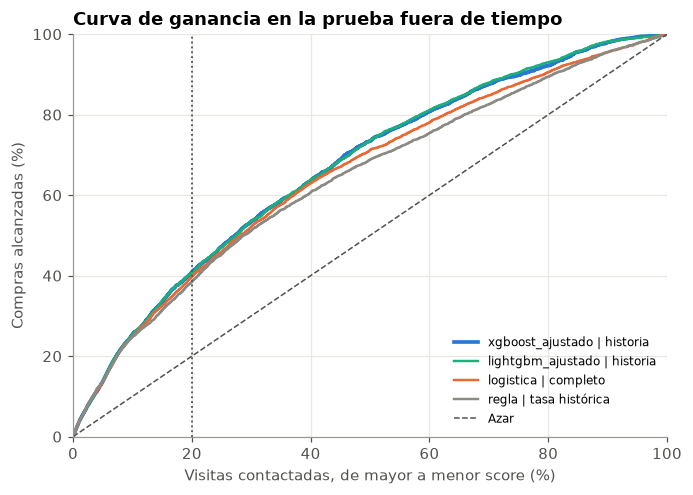

In [40]:
CUPOS = [0.05, 0.10, 0.20, 0.30, 0.50]
ids_oot = oot['id'].to_numpy()
grupos_cliente = [np.flatnonzero(ids_oot == c) for c in np.unique(ids_oot)]

def bootstrap(y_r, dic, cupos, n=N_BOOTSTRAP, semilla=SEMILLA):
    """Remuestreo pareado de clientes completos: todos los modelos se evalúan sobre las mismas muestras."""
    rng = np.random.default_rng(semilla)
    g = {k: np.empty(n) for k in dic}
    t = {k: np.empty((n, len(cupos))) for k in dic}
    for b in range(n):
        idx = np.concatenate([grupos_cliente[i] for i in rng.integers(0, len(grupos_cliente), len(grupos_cliente))])
        yb, total = y_r[idx], len(idx)
        ks = [max(1, int(total * c)) for c in cupos]
        for k, s in dic.items():
            g[k][b] = gini(yb, s[idx])
            acum = np.cumsum(yb[np.lexsort((rng.random(total), -s[idx]))])
            t[k][b] = [acum[q - 1] / q for q in ks]
    return g, t

REFERENCIAS = list(dict.fromkeys([GANADOR, ('lightgbm_ajustado', 'historia'), ('xgboost_ajustado', 'historia'),
                                   CAMPEON, ('lightgbm_ajustado', 'completo'), REGLA]))
g_boot, t_boot = bootstrap(y_oot, {c: scores[c] for c in REFERENCIAS}, CUPOS)
ic = lambda v, f=1: f'{f * np.percentile(v, 2.5):+.3f} a {f * np.percentile(v, 97.5):+.3f}'
i_cupo = CUPOS.index(CUPO)

filas = [{'Modelo': etiqueta(c), 'Gini OOT': round(gini(y_oot, scores[c]), 3), 'IC 95 % Gini': ic(g_boot[c]),
          'Tasa en cupo': pct(tasa_cupo(y_oot, scores[c], CUPO)),
          'IC 95 % tasa': f'{pct(np.percentile(t_boot[c][:, i_cupo], 2.5))} a {pct(np.percentile(t_boot[c][:, i_cupo], 97.5))}'}
         for c in REFERENCIAS]
filas.append({'Modelo': 'Azar', 'Gini OOT': 0, 'IC 95 % Gini': '', 'Tasa en cupo': pct(y_oot.mean()), 'IC 95 % tasa': ''})
display(pd.DataFrame(filas).set_index('Modelo'))

difs = pd.DataFrame([{'Comparación': f'{etiqueta(GANADOR)} − {etiqueta(c)}',
                      'Diferencia de Gini': round(gini(y_oot, scores[GANADOR]) - gini(y_oot, scores[c]), 3),
                      'IC 95 %': ic(g_boot[GANADOR] - g_boot[c])} for c in REFERENCIAS if c != GANADOR]).set_index('Comparación')
display(difs)

fig, eje = plt.subplots(figsize=(6.4, 4.6))
x = np.arange(1, len(y_oot) + 1) / len(y_oot)
CURVAS = list(dict.fromkeys([GANADOR, ('lightgbm_ajustado', 'historia'), CAMPEON, REGLA]))
for c, color in zip(CURVAS, [AZUL, VERDE, NARANJA, GRIS]):
    orden = np.lexsort((np.random.default_rng(SEMILLA).random(len(y_oot)), -scores[c]))
    eje.plot(x * 100, np.cumsum(y_oot[orden]) / y_oot.sum() * 100, color=color, label=etiqueta(c),
             linewidth=2.4 if c == GANADOR else 1.6)
eje.plot([0, 100], [0, 100], color=TINTA, linestyle='--', linewidth=1, label='Azar')
eje.axvline(CUPO * 100, color=TINTA, linestyle=':', linewidth=1.2)
eje.set(xlabel='Visitas contactadas, de mayor a menor score (%)', ylabel='Compras alcanzadas (%)',
        title='Curva de ganancia en la prueba fuera de tiempo', xlim=(0, 100), ylim=(0, 100))
eje.legend(loc='lower right', fontsize=8)
plt.tight_layout(); fig.savefig('img/curva_ganancia_oot.png', dpi=130, bbox_inches='tight'); plt.show()

**Lectura.**

- **El elegido ordena bien fuera de tiempo.** Su Gini es 0.448 (IC de 0.406 a 0.488), el tercero de 16. Con un cupo de 20 %, el 51.4 % de las visitas compra, frente a 25.2 % al azar, y se alcanza el 40.9 % de todas las compras.
- **Supera al campeón y a la regla.** Su ventaja es de 0.042 sobre el campeón (IC de +0.032 a +0.055) y de 0.077 sobre la regla (+0.061 a +0.096). Ninguno de esos intervalos incluye el cero.
- **Empata con LightGBM.** Con las mismas 4 variables, LightGBM obtiene 0.451. La diferencia es de −0.003 (IC de −0.006 a −0.000): fuera de tiempo, LightGBM ordena apenas mejor, pero la diferencia es menor que cualquier efecto práctico. Ambos algoritmos son intercambiables para este problema.
- **Menos variables rinden al menos igual.** Frente a LightGBM con las 30 candidatas (0.440), la ventaja es de 0.007 (IC de −0.000 a +0.015). Las 26 variables que el modelo no usa no mejoran la prueba final.
- **Se sostiene en el tiempo.** El Gini baja de 0.485 en desarrollo a 0.448 en OOT.

El tercer lugar y el cambio de regla de elegibilidad deben leerse con cautela (sección 16).

## 10. Calibración y proyección de demanda

Para elegir a quién dirigir una oferta basta el orden. Para proyectar cuántas compras habrá cada semana, y planificar inventario, se necesitan probabilidades correctas. Revisamos tres cosas:

- **Nivel:** si el promedio predicho coincide con la tasa real.
- **Forma:** si cada decil de score compra lo que el modelo anticipa.
- **Demanda semanal:** si la suma de probabilidades de la semana se parece a las compras registradas.

**Brier.** Es el promedio de $(p - y)^2$. Lo comparamos con una referencia que asigna a todas las visitas la tasa de entrenamiento.

,Promedio predicho,Tasa real,Brier
Enfoque,,,
Modelo elegido,25.2 %,25.2 %,0.1627
Tasa de entrenamiento para todos,24.9 %,25.2 %,0.1883


Predicho frente a observado por decil (%): 8/5, 11/14, 13/12, 15/17, 18/18, 21/25, 25/26, 31/32, 41/39, 69/64
Error absoluto medio de la demanda semanal: 17.2 % | sesgo total: 0.3 %


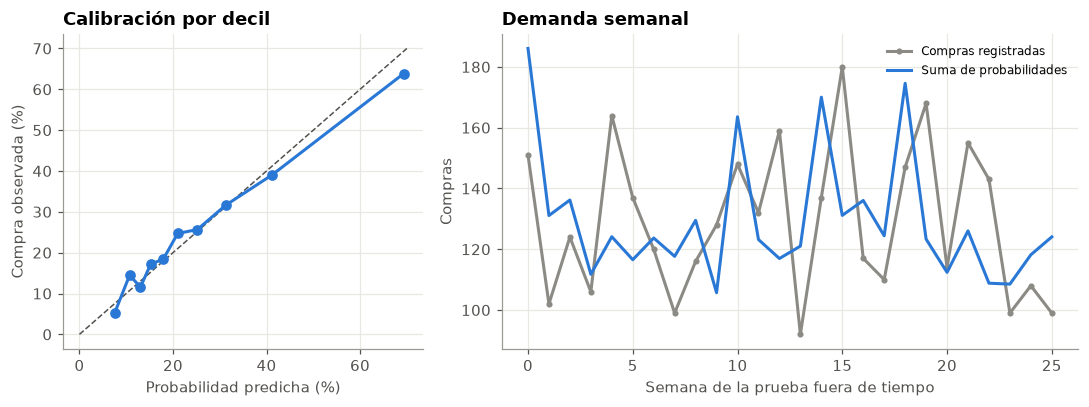

In [41]:
p_oot = scores[GANADOR]
tasa_train = y[mascara_train(INICIO_OOT)].mean()
cal = pd.DataFrame({'Enfoque': ['Modelo elegido', 'Tasa de entrenamiento para todos'],
                    'Promedio predicho': [pct(p_oot.mean()), pct(tasa_train)], 'Tasa real': [pct(y_oot.mean())] * 2,
                    'Brier': [round(brier_score_loss(y_oot, p_oot), 4), round(brier_score_loss(y_oot, np.full(len(y_oot), tasa_train)), 4)]})
display(cal.set_index('Enfoque'))

decil = pd.qcut(p_oot, 10, labels=False, duplicates='drop')
por_decil = pd.DataFrame({'p': p_oot, 'y': y_oot, 'd': decil}).groupby('d').mean()
semana = (oot['dia_visita'].to_numpy() - INICIO_OOT) // 7
demanda = pd.DataFrame({'semana': semana, 'p': p_oot, 'y': y_oot}).groupby('semana').agg(predicho=('p', 'sum'), real=('y', 'sum'), visitas=('y', 'size'))
demanda = demanda[demanda['visitas'] >= 200]
error_semanal = (demanda['predicho'] - demanda['real']).abs() / demanda['real']
print('Predicho frente a observado por decil (%):', ', '.join(f'{100 * a:.0f}/{100 * b:.0f}' for a, b in zip(por_decil['p'], por_decil['y'])))
print(f'Error absoluto medio de la demanda semanal: {pct(error_semanal.mean())} | sesgo total: {pct(demanda["predicho"].sum() / demanda["real"].sum() - 1)}')

fig, (e1, e2) = plt.subplots(1, 2, figsize=(10, 3.8), width_ratios=[1, 1.6])
e1.plot([0, 70], [0, 70], color=TINTA, linestyle='--', linewidth=1)
e1.plot(por_decil['p'] * 100, por_decil['y'] * 100, color=AZUL, marker='o')
e1.set(xlabel='Probabilidad predicha (%)', ylabel='Compra observada (%)', title='Calibración por decil')
e2.plot(demanda.index, demanda['real'], color=GRIS, marker='o', markersize=3, label='Compras registradas')
e2.plot(demanda.index, demanda['predicho'], color=AZUL, label='Suma de probabilidades')
e2.set(xlabel='Semana de la prueba fuera de tiempo', ylabel='Compras', title='Demanda semanal')
e2.legend(fontsize=8)
plt.tight_layout(); fig.savefig('img/calibracion_demanda.png', dpi=130, bbox_inches='tight'); plt.show()

**Lectura.** La calibración es buena. El modelo predice 25.2 % y ocurre 25.2 %, y el Brier mejora 14 % frente a asignar la misma tasa a todos (0.1627 frente a 0.1883). En cada decil, lo predicho y lo observado difieren en 5 puntos o menos. Por ejemplo, el decil superior predice 69 % y ocurre 64 %.

Para proyectar demanda, la suma semanal no tiene sesgo (+0.3 %), pero su error medio es 17.2 %. Con unas 130 compras por semana, el azar por sí solo explica errores de alrededor de 9 %. El resto viene de que el modelo no usa el precio de la semana. Sirve para planificar el volumen total, pero para anticipar cada semana conviene combinarlo con el modelo de precio de la sección 13.

## 11. Análisis de sensibilidad

Un resultado robusto no debería depender de un detalle. La celda siguiente hace cuatro preguntas:

1. **¿Cambia si validamos al azar?** La validación cruzada mezcla días y puede ser optimista.
2. **¿Funciona con clientes que nunca vio?** Entrenamos sin el 20 % de los clientes y evaluamos en ellos.
3. **¿De qué información depende?** Retiramos cada grupo de variables que el modelo usa y agregamos cada grupo que no usa, con todas sus candidatas, incluidas las descartadas en la sección 7.
4. **¿Depende de la semilla?** Reentrenamos con cinco semillas.

Estas pruebas buscan los puntos débiles del modelo. Por eso no se usan para volver a elegirlo.

In [42]:
alg_g = GANADOR[0] if GANADOR[0] != 'regla' else 'logistica'
vars_g = ajustes[GANADOR].variables if GANADOR[0] != 'regla' else HISTORIA
base_gini = gini(y_oot, scores[GANADOR])

# 1. Validación cruzada aleatoria de 5 particiones
ginis_cv = []
for tr_, te_ in StratifiedKFold(5, shuffle=True, random_state=SEMILLA).split(df, y):
    m_tr = np.zeros(len(df), dtype=bool); m_tr[tr_] = True
    ginis_cv.append(gini(y[te_], ajustar(alg_g, vars_g, m_tr).predecir(df.iloc[te_])))
print('1. Validación cruzada aleatoria (5 particiones)')
print(f'   Gini medio {np.mean(ginis_cv):.3f} | desviación {np.std(ginis_cv):.3f} | Gini OOT temporal {base_gini:.3f}')

# 2. Clientes nuevos: el 20 % de los clientes no participa en el entrenamiento
rng = np.random.default_rng(SEMILLA)
nuevos = rng.choice(df['id'].unique(), size=df['id'].nunique() // 5, replace=False)
es_nuevo = df['id'].isin(nuevos).to_numpy()
aj_sin = ajustar(alg_g, vars_g, mascara_train(INICIO_OOT) & ~es_nuevo)
en_n = es_nuevo[en_oot]
print('2. Clientes no vistos en el entrenamiento')
print(f'   Gini en esos {len(nuevos)} clientes: entrenando sin ellos {gini(y_oot[en_n], aj_sin.predecir(oot[en_n])):.3f} '
      f'| entrenando con ellos {gini(y_oot[en_n], scores[GANADOR][en_n]):.3f}')

# 3. Retirar los grupos que el modelo usa o agregar los que no usa
print('3. Retirar o agregar grupos de variables (Gini OOT)')
for nombre, grupo in [('historia', HISTORIA), ('precio', PRECIO), ('cliente', CLIENTE)]:
    presentes = [v for v in vars_g if v in grupo]
    if presentes and len(presentes) < len(vars_g):
        prueba, texto = [v for v in vars_g if v not in grupo], f'Sin {nombre}'
    elif not presentes:
        prueba, texto = vars_g + grupo, f'Con todas las candidatas de {nombre}'
    else:
        continue
    g_r = gini(y_oot, ajustar(alg_g, prueba, mascara_train(INICIO_OOT)).predecir(oot))
    print(f'   {texto:38s} {g_r:.3f} ({g_r - base_gini:+.3f})')

# 4. Semillas
if alg_g.startswith(('lightgbm', 'xgboost')):
    semillas = []
    for s in range(5):
        m = crear(alg_g, vars_g).set_params(random_state=s).fit(df.loc[mascara_train(INICIO_OOT), vars_g], y[mascara_train(INICIO_OOT)])
        semillas.append(gini(y_oot, m.predict_proba(oot[vars_g])[:, 1]))
    print(f'4. Cinco semillas: Gini OOT entre {min(semillas):.3f} y {max(semillas):.3f}')
else:
    print('4. Cinco semillas: no aplica, la logística no depende del azar')

1. Validación cruzada aleatoria (5 particiones)
   Gini medio 0.480 | desviación 0.009 | Gini OOT temporal 0.448


2. Clientes no vistos en el entrenamiento
   Gini en esos 100 clientes: entrenando sin ellos 0.390 | entrenando con ellos 0.391
3. Retirar o agregar grupos de variables (Gini OOT)


   Con todas las candidatas de precio     0.431 (-0.017)


   Con todas las candidatas de cliente    0.445 (-0.003)


4. Cinco semillas: Gini OOT entre 0.448 y 0.449


**Lectura.**

1. **Validar al azar es optimista.** La validación cruzada aleatoria da un Gini de 0.480, contra 0.448 en la evaluación temporal. Al mezclar días, el modelo ve visitas vecinas del mismo cliente. La brecha es moderada porque las variables elegidas son estables.
2. **Funciona con clientes nuevos.** En 100 clientes que no participaron del entrenamiento, el Gini es 0.390, igual que si se los incluye (0.391). Las variables de historia describen comportamientos generales, no a clientes concretos.
3. **Agregar lo descartado empeora el modelo.** Con todas las candidatas de precio, el Gini OOT baja a 0.431 (−0.017). Con todas las del perfil del cliente, baja a 0.445 (−0.003). La selección de la sección 7 se confirma fuera de tiempo.
4. **No depende de la semilla.** Con cinco semillas, el Gini OOT queda entre 0.448 y 0.449.

## 12. Interpretabilidad y equidad

**SHAP.** Reparte cada predicción entre las variables, como si cada una aportara una parte del resultado. LightGBM lo calcula de forma exacta con `pred_contrib=True`. Promediando esos aportes en valor absoluto vemos cuánto usa cada variable el modelo. Lo calculamos sobre el LightGBM ajustado con todas las variables, aunque no sea el elegido, para ver qué aprovecha un modelo complejo.

**Odds ratio.** Lo calculamos con la logística de las variables seleccionadas. Las chances son `p / (1 − p)`, y el odds ratio compara las chances antes y después de mover una variable. En la logística, el valor para `+1 desviación` indica cuánto se multiplican las chances cuando la variable sube una desviación estándar. Un valor de 1 indica que no hay efecto.

**Equidad.** Comparamos el desempeño y la selección por género, edad y segmento. `Seleccionadas en el cupo` debería parecerse a su tasa de compra relativa: un grupo que compra más recibirá más ofertas. No usar una variable sensible no garantiza un resultado equitativo, porque otras variables pueden estar relacionadas con ella.

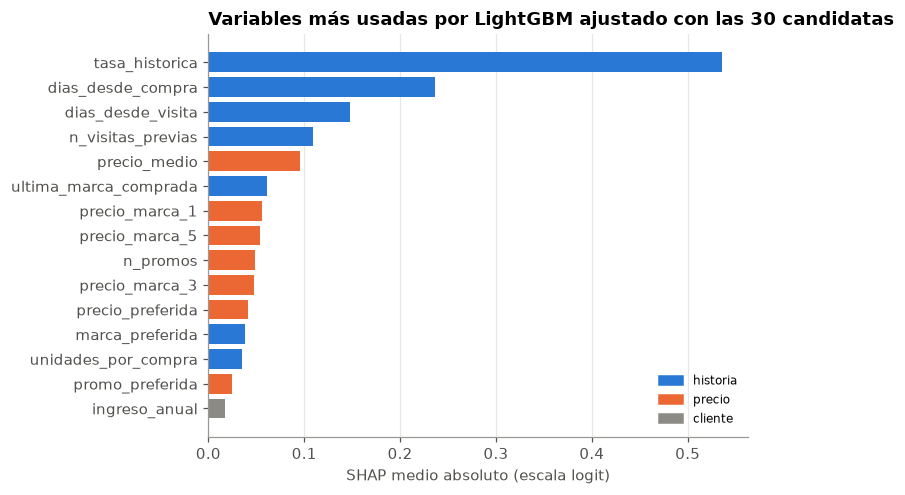

Participación de cada grupo en el SHAP total: {'cliente': '2.5 %', 'historia': '72.6 %', 'precio': '24.9 %'}
Cinco variables con mayor SHAP medio: tasa_historica (0.536), dias_desde_compra (0.237), dias_desde_visita (0.148), n_visitas_previas (0.110), precio_medio (0.096)


,Coeficiente,Odds ratio
tasa_historica,0.712,2.038
ocupacion_2,-0.340,0.712
ultima_marca_comprada_3,-0.307,0.736
dias_desde_compra,-0.302,0.740
segmento_2,-0.251,0.778
segmento_0,-0.235,0.790
ultima_marca_comprada_2,-0.234,0.791
segmento_1,-0.226,0.798
ultima_marca_comprada_5,0.195,1.215
ocupacion_0,-0.188,0.829


In [43]:
aj_arbol = ajustes[('lightgbm_ajustado', 'completo')]
contrib = aj_arbol.modelo.predict(oot[aj_arbol.variables], pred_contrib=True)[:, :-1]
shap_medio = pd.Series(np.abs(contrib).mean(axis=0), index=aj_arbol.variables).sort_values()
color_grupo = {'historia': AZUL, 'precio': NARANJA, 'cliente': GRIS}
top = shap_medio.tail(15)
fig, eje = plt.subplots(figsize=(7, 4.6))
eje.barh(top.index, top, color=[color_grupo[grupo_de[v]] for v in top.index])
eje.set(xlabel='SHAP medio absoluto (escala logit)', title='Variables más usadas por LightGBM ajustado con las 30 candidatas')
eje.grid(axis='y', visible=False)
eje.legend(handles=[Patch(color=col, label=nombre) for nombre, col in color_grupo.items()], loc='lower right', fontsize=8)
plt.tight_layout(); fig.savefig('img/shap_modelo_completo.png', dpi=130, bbox_inches='tight'); plt.show()
por_grupo = shap_medio.groupby(shap_medio.index.map(grupo_de)).sum()
print('Participación de cada grupo en el SHAP total:', {k: pct(v / por_grupo.sum()) for k, v in por_grupo.items()})
print('Cinco variables con mayor SHAP medio:', ', '.join(f'{v} ({x:.3f})' for v, x in shap_medio.tail(5)[::-1].items()))

pipe = ajustes[('logistica', 'seleccionado')].modelo
nombres = [n.split('__', 1)[1] for n in pipe.steps[0][1].get_feature_names_out()]
pesos = pd.Series(pipe.steps[-1][1].coef_[0], index=nombres)
odds = pd.DataFrame({'Coeficiente': pesos, 'Odds ratio': np.exp(pesos)})
odds.reindex(pesos.abs().sort_values(ascending=False).index).head(12).round(3)

In [44]:
p_sel = scores[GANADOR]
umbral = np.sort(p_sel)[::-1][int(len(p_sel) * CUPO) - 1]
eval_eq = oot.assign(p=p_sel, y=y_oot, sel=p_sel >= umbral,
                     edad_tramo=pd.cut(oot['edad'], [0, 29, 44, 59, 100], labels=['18-29', '30-44', '45-59', '60+']),
                     segmento_n=oot['segmento'].map(NOMBRES))
filas = []
for v in ['genero', 'edad_tramo', 'segmento_n']:
    for grupo, sub in eval_eq.groupby(v, observed=True):
        filas.append({'Variable': v, 'Grupo': grupo, 'Visitas': len(sub), 'Tasa real': pct(sub['y'].mean()),
                      'Predicho': pct(sub['p'].mean()), 'Gini': round(gini(sub['y'], sub['p']), 3),
                      'Seleccionadas en el cupo': pct(sub['sel'].mean())})
pd.DataFrame(filas).set_index(['Variable', 'Grupo'])

Visitas Tasa real Predicho   Gini Seleccionadas en el cupo
Variable   Grupo                                                                               
genero     0                            8133    25.4 %   26.2 %  0.478                   21.2 %
           1                            5198    24.8 %   23.7 %  0.398                   18.2 %
edad_tramo 18-29                        3370    22.1 %   20.8 %  0.379                   12.5 %
           30-44                        6158    26.1 %   25.4 %  0.458                   19.3 %
           45-59                        2715    26.9 %   29.2 %  0.497                   28.6 %
           60+                          1088    25.3 %   28.0 %  0.421                   25.9 %
segmento_n Adultos de ingreso medio     5544    26.4 %   26.2 %  0.512                   20.8 %
           Jóvenes de menor ingreso     4973    23.0 %   21.9 %  0.351                   14.3 %
           Mayores de mayor ingreso     2814    26.7 %   29.1 %  0.460                   28.5 %

**Lectura.**

- **SHAP del modelo completo.** El LightGBM con las 30 candidatas asigna el 72.6 % de su uso a la historia, el 24.9 % al precio y el 2.5 % al perfil. Entre sus cinco variables principales están `n_visitas_previas` y `precio_medio`, dos variables que la sección 7 descartó por inestables. Por eso no ordena mejor fuera de tiempo que el modelo elegido (0.440 frente a 0.448).
- **Logística con las variables seleccionadas.** Una desviación más de tasa histórica multiplica por 2.04 las chances de comprar. Una desviación más de días sin comprar las reduce 26 %. Como no hay categoría base, cada categoría se compara con el promedio de su variable. Entre las marcas de la visita anterior, la marca 5 es la de más chances (1.22) y la marca 3 la de menos (0.74).
- **Equidad.** El modelo ordena peor dentro del género 1 (Gini 0.398 frente a 0.478) y entre los jóvenes de menor ingreso (0.351). Ese segmento recibe 14.3 % de las ofertas con una tasa real de 23.0 %, mientras el grupo de 45 a 59 años recibe 28.6 %. El modelo no usa ninguna variable del perfil, así que la diferencia viene de la historia de compra: los jóvenes compran con menos regularidad. Si la oferta es un beneficio, este desbalance debe vigilarse.

Estos pesos describen asociaciones, no efectos causales.

## 13. Precio: elasticidad de compra y elección de marca

El modelo de propensión no usa el precio: la sección 7 mostró que las variables de precio no sirven para ordenar clientes, porque son iguales para todos en un día y cambian por épocas. Pero el precio sí cambia **cuánto** se compra cada día, y esa es la pregunta de pricing. Para responderla estimamos un modelo aparte, pequeño y legible.

**Modelo de respuesta al precio.** Una regresión logística sin penalización:

$$\text{logit}(P) = a + b \cdot \text{precio medio} + c \cdot \text{marcas en promoción} + \text{controles de historia}$$

Los controles son la tasa histórica, la compra en la visita anterior y los días desde la visita anterior. Separan el efecto del precio del hábito de cada cliente.

**De coeficiente a elasticidad.** En una logística, la elasticidad de la probabilidad de compra respecto al precio es:

$$\varepsilon_i = b \cdot \text{precio}_i \cdot (1 - P_i)$$

Promediamos $\varepsilon_i$ sobre las visitas. Una elasticidad de −2 significa que subir todos los precios un 1 % reduce la probabilidad de compra un 2 %. Si su valor absoluto supera 1, la demanda es **elástica**.

**La unidad de remuestreo son los días.** El precio es el mismo para todos los clientes de un día, así que la información sobre el precio proviene de 727 días, no de 58 mil visitas. El intervalo se calcula remuestreando días completos. Remuestrear visitas daría un intervalo falsamente estrecho.

In [45]:
CONTROLES = ['tasa_historica', 'compro_visita_anterior', 'dias_desde_visita']
df['trimestre'] = (df['dia_visita'] - 1) // 91
TRIM = [f'trim_{t}' for t in sorted(df['trimestre'].unique())[1:]]
MESES = [f'mes_{m}' for m in sorted(df['mes'].unique())[1:]]
for t in sorted(df['trimestre'].unique())[1:]:
    df[f'trim_{t}'] = (df['trimestre'] == t).astype(float)
for m in sorted(df['mes'].unique())[1:]:
    df[f'mes_{m}'] = (df['mes'] == m).astype(float)

class ModeloPrecio:
    """Logística de respuesta al precio. El precio queda en su escala original; el resto se estandariza."""
    def __init__(self, precio='precio_medio', otras=('n_promos', *CONTROLES)):
        self.precio, self.otras = precio, list(otras)

    def _X(self, d, factor=1.0):
        X = d[[self.precio] + self.otras].to_numpy(float).copy()
        X[:, 0] *= factor
        return (X - self.mu_) / self.sd_

    def fit(self, d):
        X = d[[self.precio] + self.otras].to_numpy(float)
        self.mu_, self.sd_ = X.mean(axis=0), X.std(axis=0)
        self.mu_[0], self.sd_[0] = 0.0, 1.0
        self.sd_[self.sd_ == 0] = 1.0
        self.m_ = LogisticRegression(penalty=None, max_iter=5000).fit(self._X(d), d['incidencia_compra'])
        self.b_ = float(self.m_.coef_[0][0])
        return self

    def prob(self, d, factor=1.0):
        return self.m_.predict_proba(self._X(d, factor))[:, 1]

    def elasticidad(self, d):
        return float(np.mean(self.b_ * d[self.precio].to_numpy() * (1 - self.prob(d))))

indices_dia = df.groupby('dia_visita').indices
def ic_dias(d, crear_modelo, n=N_BOOT_DIAS, semilla=SEMILLA):
    """Intervalo de la elasticidad remuestreando días completos."""
    rng = np.random.default_rng(semilla)
    idx_dia = d.groupby('dia_visita').indices
    claves = np.array(list(idx_dia))
    vals = []
    for _ in range(n):
        filas_b = np.concatenate([idx_dia[k] for k in rng.choice(claves, len(claves))])
        sub = d.iloc[filas_b]
        vals.append(crear_modelo().fit(sub).elasticidad(sub))
    return np.percentile(vals, [2.5, 97.5])

In [46]:
ESPECIFICACIONES = {
    'A. Solo precio medio': lambda: ModeloPrecio(otras=()),
    'B. + marcas en promoción': lambda: ModeloPrecio(otras=('n_promos',)),
    'C. + historia (principal)': lambda: ModeloPrecio(),
    'D. C + efectos de trimestre': lambda: ModeloPrecio(otras=('n_promos', *CONTROLES, *TRIM)),
    'E. C + efectos de mes': lambda: ModeloPrecio(otras=('n_promos', *CONTROLES, *MESES)),
    'F. Precio de la marca preferida': lambda: ModeloPrecio('precio_preferida', ('promo_preferida', *CONTROLES)),
}
periodos = {'Desarrollo (días < 548)': df[df['dia_visita'] < INICIO_OOT], 'OOT': df[df['dia_visita'] >= INICIO_OOT], 'Total': df}
filas = []
for nombre, crear_m in ESPECIFICACIONES.items():
    fila = {'Especificación': nombre}
    for per, d in periodos.items():
        fila[per] = round(crear_m().fit(d).elasticidad(d), 2)
    filas.append(fila)
robustez = pd.DataFrame(filas).set_index('Especificación')
lo, hi = ic_dias(df, ESPECIFICACIONES['C. + historia (principal)'])
modelo_total = ModeloPrecio().fit(df)
ELASTICIDAD = modelo_total.elasticidad(df)
print(f'Elasticidad principal (C, total): {ELASTICIDAD:.2f} | IC 95 % por días: {lo:.2f} a {hi:.2f}')
robustez

Elasticidad principal (C, total): -3.29 | IC 95 % por días: -4.75 a -0.74


,Desarrollo (días < 548),OOT,Total
Especificación,,,
A. Solo precio medio,-4.64,-3.63,-3.51
B. + marcas en promoción,-3.17,-2.72,-2.23
C. + historia (principal),-4.34,-3.03,-3.29
D. C + efectos de trimestre,-5.14,-5.12,-5.04
E. C + efectos de mes,-5.27,-6.90,-5.58
F. Precio de la marca preferida,0.08,-0.34,-0.05


**Lectura.**

- **La compra es elástica al precio.** La elasticidad principal es −3.29: si todos los precios suben 1 %, la probabilidad de compra cae alrededor de 3.3 %. El intervalo por días es amplio (−4.75 a −0.74), pero excluye el cero.
- **El signo es estable.** Las seis especificaciones con precio medio dan valores negativos en desarrollo, OOT y total. Al agregar efectos de trimestre o de mes, la elasticidad se vuelve más negativa (−5.0 a −5.6). El efecto no es un artefacto de una tendencia: aparece dentro de cada período.
- **Importa el precio de la categoría, no el de la marca habitual.** Con el precio de la marca preferida, la elasticidad es prácticamente cero (−0.05). La segunda tabla lo confirma: la compra responde sobre todo a los precios de las marcas 1, 2 y 3, con elasticidades cercanas a −0.85, y casi nada al de la marca 5. Un cliente que ve barata la categoría compra, aunque termine eligiendo otra marca.

### 13.1 Prueba de nivel: ¿la elasticidad anticipa lo que pasó después?

Una elasticidad estimada con variaciones de un día a otro puede no describir un cambio de precio sostenido. Si el precio sube solo un día, el cliente puede postergar la compra a otra visita. Si sube para siempre, no tiene a dónde moverla.

Lo probamos así: estimamos el modelo con los datos de desarrollo y le pedimos que anticipe la tasa de cada mes de la prueba OOT, cuando el precio medio fue más alto. Si la elasticidad describiera bien un cambio sostenido, la tasa debería haber caído.

In [47]:
dev, fut = df[df['dia_visita'] < INICIO_OOT], df[df['dia_visita'] >= INICIO_OOT]
con_precio = ModeloPrecio().fit(dev)
sin_precio = ModeloPrecio('n_promos', CONTROLES).fit(dev)
fut_ = fut.assign(con=con_precio.prob(fut), sin=sin_precio.prob(fut))
nivel = fut_.groupby('mes').agg(**{'Precio medio': ('precio_medio', 'mean'), 'Tasa real': ('incidencia_compra', 'mean'),
                                  'Modelo con precio': ('con', 'mean'), 'Modelo sin precio': ('sin', 'mean')})
nivel.loc['Total OOT'] = [fut['precio_medio'].mean(), fut['incidencia_compra'].mean(), fut_['con'].mean(), fut_['sin'].mean()]
print(f'Precio medio: desarrollo {dev["precio_medio"].mean():.3f} | OOT {fut["precio_medio"].mean():.3f} '
      f'({fut["precio_medio"].mean() / dev["precio_medio"].mean() - 1:+.1%})')
nivel.assign(**{c: nivel[c].map(pct) for c in ['Tasa real', 'Modelo con precio', 'Modelo sin precio']}).round(3)

Precio medio: desarrollo 1.986 | OOT 2.042 (+2.8%)


,Precio medio,Tasa real,Modelo con precio,Modelo sin precio
mes,,,,
19,2.015,21.7 %,25.3 %,26.3 %
20,1.997,27.1 %,25.5 %,26.4 %
21,2.044,24.7 %,22.8 %,25.0 %
22,2.055,28.0 %,24.1 %,27.8 %
23,2.067,23.9 %,22.4 %,25.8 %
24,2.052,24.9 %,21.3 %,23.5 %
25,2.092,26.2 %,19.3 %,22.6 %
Total OOT,2.042,25.2 %,23.3 %,25.6 %


**Lectura.** El precio medio de la prueba OOT fue 2.8 % más alto que en desarrollo, y la tasa de compra no cayó: fue 25.2 %. El modelo con precio anticipaba 23.3 %, y el error crece en los meses más caros. En el mes 25, con el precio más alto, predijo 19.3 % y ocurrió 26.2 %. El modelo sin precio acertó mejor el nivel total (25.6 %).

**Conclusión.** La elasticidad de −3.3 describe la **respuesta de corto plazo**: el cliente decide en qué visita comprar según el precio del día. No describe cuánto cae la compra si el precio sube de forma sostenida, que parece mucho menor. Por eso, las simulaciones de la sección 14 son un **límite superior** de la respuesta al precio.

In [48]:
modelos_seg, elas_seg = {}, []
for s in sorted(df['segmento'].unique()):
    d = df[df['segmento'] == s]
    modelos_seg[s] = ModeloPrecio().fit(d)
    lo_s, hi_s = ic_dias(d, ModeloPrecio)
    p_base = modelos_seg[s].prob(d)
    elas_seg.append({'Segmento': NOMBRES[s], 'Visitas': len(d), 'Tasa de compra': pct(d['incidencia_compra'].mean()),
                     'Coeficiente del precio': round(modelos_seg[s].b_, 2), 'Elasticidad': round(modelos_seg[s].elasticidad(d), 2),
                     'IC 95 % (días)': f'{lo_s:.2f} a {hi_s:.2f}',
                     'Cambio en compras si el precio sube 1 %': pct(modelos_seg[s].prob(d, 1.01).mean() / p_base.mean() - 1, 2)})
display(pd.DataFrame(elas_seg).set_index('Segmento'))

marca_m = ModeloPrecio(PRECIOS[0], (*PRECIOS[1:], *PROMOS, *CONTROLES)).fit(df)
p_m = marca_m.prob(df)
coefs = marca_m.m_.coef_[0][:5] / marca_m.sd_[:5]
pd.DataFrame({'Marca': list(MARCAS), 'Precio medio': [df[p].mean() for p in PRECIOS],
              'Elasticidad de la compra de la categoría': [float(np.mean(c * df[p] * (1 - p_m))) for c, p in zip(coefs, PRECIOS)]}).set_index('Marca').round(2)

,Visitas,Tasa de compra,Coeficiente del precio,Elasticidad,IC 95 % (días),Cambio en compras si el precio sube 1 %
Segmento,,,,,,
Jóvenes de menor ingreso,21625,21.2 %,-2.33,-3.68,-5.70 a -0.88,-3.32 %
Adultos de ingreso medio,24443,26.5 %,-2.83,-4.16,-6.08 a -2.37,-3.23 %
Mayores de mayor ingreso,12486,28.8 %,-0.41,-0.58,-3.28 a 0.90,-0.50 %


,Precio medio,Elasticidad de la compra de la categoría
Marca,,
1,1.39,-0.87
2,1.78,-0.83
3,2.01,-0.82
4,2.16,-0.45
5,2.65,0.29


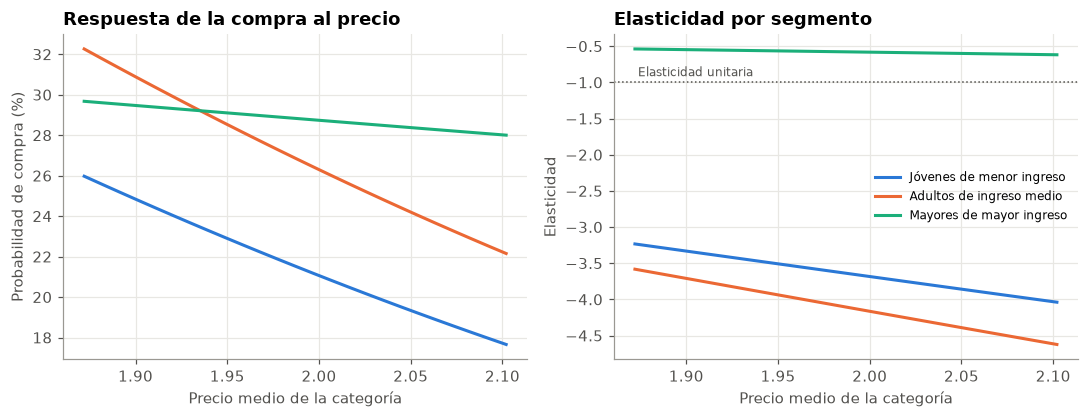

Rango observado del precio medio: 1.87 a 2.10; las curvas no se extrapolan fuera de él.


In [49]:
rejilla = np.linspace(df['precio_medio'].min(), df['precio_medio'].max(), 25)
fig, (e1, e2) = plt.subplots(1, 2, figsize=(10, 3.9))
for (s, mod), color in zip(modelos_seg.items(), [AZUL, NARANJA, VERDE, GRIS]):
    d = df[df['segmento'] == s]
    probs, elas = [], []
    for precio in rejilla:
        X = d.copy(); X['precio_medio'] = precio
        p = mod.prob(X)
        probs.append(p.mean() * 100); elas.append(np.mean(mod.b_ * precio * (1 - p)))
    e1.plot(rejilla, probs, color=color, label=NOMBRES[s]); e2.plot(rejilla, elas, color=color, label=NOMBRES[s])
e1.set(xlabel='Precio medio de la categoría', ylabel='Probabilidad de compra (%)', title='Respuesta de la compra al precio')
e2.axhline(-1, color=TINTA, linestyle=':', linewidth=1)
e2.annotate('Elasticidad unitaria', (rejilla[0], -1), xytext=(2, 4), textcoords='offset points', color=TINTA, fontsize=8)
e2.set(xlabel='Precio medio de la categoría', ylabel='Elasticidad', title='Elasticidad por segmento')
e2.legend(fontsize=8)
plt.tight_layout(); fig.savefig('img/elasticidad_segmentos.png', dpi=130, bbox_inches='tight'); plt.show()
print(f'Rango observado del precio medio: {rejilla[0]:.2f} a {rejilla[-1]:.2f}; las curvas no se extrapolan fuera de él.')

**Lectura.**

- **Dos segmentos elásticos.** Los jóvenes de menor ingreso (−3.68) y los adultos de ingreso medio (−4.16) responden con fuerza al precio. El intervalo de los adultos de ingreso medio es el más preciso (−6.08 a −2.37).
- **Un segmento casi insensible.** En los mayores de mayor ingreso, la elasticidad es −0.58 y su intervalo incluye el cero (−3.28 a 0.90). Un 1 % de aumento les reduce la compra apenas 0.5 %.
- **Las curvas no se extrapolan.** El precio medio solo varió entre 1.87 y 2.10. Fuera de ese rango, el modelo no tiene evidencia.

Recordemos la prueba de nivel: estas elasticidades describen la respuesta de un día a otro. Para un cambio sostenido, la respuesta probablemente es menor en todos los segmentos.

### 13.2 Elección de marca: ¿qué producto compra?

El modelo de propensión responde si el cliente comprará en la categoría. Para responder si comprará **un producto determinado**, agregamos un segundo modelo: dada una compra, ¿qué marca elige?

$$P(\text{compra la marca } j) = P(\text{compra}) \times P(\text{marca } j \mid \text{compra})$$

**Modelo de elección.** Una regresión logística multinomial entrenada con las compras de desarrollo. Usa los precios y promociones del día de las 5 marcas y la **cuota histórica** de cada marca en las compras anteriores del cliente, que mide su lealtad. Un cliente sin compras previas recibe 20 % en cada marca.

Lo comparamos con dos referencias: las cuotas de mercado, que dan a todos las mismas probabilidades, y la marca preferida, que predice la marca más comprada por el cliente. El **acierto** es la proporción de compras en las que la marca más probable fue la elegida. La **log loss** mide la calidad de las probabilidades: menor es mejor.

In [50]:
CUOTAS = [f'cuota_marca_{m}' for m in MARCAS]
conteo_marca = np.column_stack([(df['id_marca'] == m).astype(int).groupby(df['id']).cumsum() - (df['id_marca'] == m).astype(int)
                                for m in MARCAS])
total_previas = conteo_marca.sum(axis=1, keepdims=True)
df[CUOTAS] = np.where(total_previas > 0, conteo_marca / np.maximum(total_previas, 1), 1 / len(MARCAS))
VARS_MARCA = PRECIOS + PROMOS + CUOTAS
es_compra = df['incidencia_compra'].to_numpy() == 1
tr_m, te_m = es_compra & mascara_train(INICIO_OOT), es_compra & en_oot

def crear_modelo_marca():
    return make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000))

modelo_marca = crear_modelo_marca().fit(df.loc[tr_m, VARS_MARCA], df.loc[tr_m, 'id_marca'])
p_marca_te = modelo_marca.predict_proba(df.loc[te_m, VARS_MARCA])
y_marca_te = df.loc[te_m, 'id_marca'].to_numpy()
cuota_mercado = df.loc[tr_m, 'id_marca'].value_counts(normalize=True).sort_index().to_numpy()
preferida_te = df.loc[te_m, CUOTAS].to_numpy().argmax(axis=1) + 1
print(f'Compras: {int(tr_m.sum()):,} en desarrollo y {int(te_m.sum()):,} en OOT')
pd.DataFrame({
    'Acierto de la marca': [pct((y_marca_te == cuota_mercado.argmax() + 1).mean()), pct((preferida_te == y_marca_te).mean()),
                            pct((modelo_marca.classes_[p_marca_te.argmax(axis=1)] == y_marca_te).mean())],
    'Log loss': [round(log_loss(y_marca_te, np.tile(cuota_mercado, (len(y_marca_te), 1)), labels=list(MARCAS)), 3), np.nan,
                 round(log_loss(y_marca_te, p_marca_te, labels=modelo_marca.classes_), 3)],
}, index=['Cuotas de mercado', 'Marca preferida del cliente', 'Modelo multinomial'])

Compras: 11,283 en desarrollo y 3,355 en OOT


,Acierto de la marca,Log loss
Cuotas de mercado,29.1 %,1.514
Marca preferida del cliente,78.5 %,NaN
Modelo multinomial,76.8 %,0.743


**Lectura.** La marca la decide sobre todo la lealtad. Predecir la marca más comprada por el cliente acierta en 78.5 % de las compras de la prueba OOT, frente a 29.1 % si se predice siempre la marca más vendida. El modelo multinomial acierta algo menos (76.8 %), pero da mejores probabilidades: su log loss es 0.743, la mitad que con las cuotas de mercado (1.514). Los precios no cambian cuál es la marca más probable, pero sí cuánto: eso es lo que necesita el pricing.

### 13.3. Elasticidades de elección de marca

Con el modelo multinomial estimado con todas las compras, subimos 1 % el precio de una marca y medimos cuánto cambia la probabilidad de elegir cada marca. La **diagonal** es la elasticidad propia: debería ser negativa. Fuera de la diagonal están las **elasticidades cruzadas**: si son positivas, las dos marcas compiten, porque al encarecerse una se elige más la otra.

El intervalo de la elasticidad propia se calcula remuestreando días completos, como en la sección anterior.

In [51]:
compras = df[es_compra].reset_index(drop=True)
modelo_marca_total = crear_modelo_marca().fit(compras[VARS_MARCA], compras['id_marca'])

def matriz_eleccion(modelo, d):
    base = modelo.predict_proba(d[VARS_MARCA]).mean(axis=0)
    filas = []
    for precio in PRECIOS:
        x = d[VARS_MARCA].copy()
        x[precio] = x[precio] * 1.01
        filas.append(modelo.predict_proba(x).mean(axis=0) / base - 1)
    return pd.DataFrame(filas, index=[f'Sube la marca {m}' for m in MARCAS], columns=[f'Marca {m}' for m in MARCAS])

matriz = matriz_eleccion(modelo_marca_total, compras)
rng = np.random.default_rng(SEMILLA)
idx_dia_c = compras.groupby('dia_visita').indices
claves_c = np.array(list(idx_dia_c))
propias = []
for _ in range(N_BOOT_DIAS):
    sub = compras.iloc[np.concatenate([idx_dia_c[k] for k in rng.choice(claves_c, len(claves_c))])]
    propias.append(np.diag(matriz_eleccion(crear_modelo_marca().fit(sub[VARS_MARCA], sub['id_marca']), sub)))
propias = np.array(propias)
display((matriz * 100).round(2))

# Elasticidad total de comprar cada marca: incidencia de la categoría × elección de marca
inc_base = marca_m.prob(df)
elig_base = modelo_marca_total.predict_proba(df[VARS_MARCA])
filas = []
for j, precio in enumerate(PRECIOS):
    x = df.copy()
    x[precio] = x[precio] * 1.01
    inc = marca_m.prob(x)
    elig = modelo_marca_total.predict_proba(x[VARS_MARCA])[:, j]
    filas.append({'Marca': j + 1, 'Participación en compras': pct((compras['id_marca'] == j + 1).mean()),
                  'Incidencia de la categoría': round((inc.mean() / inc_base.mean() - 1) * 100, 2),
                  'Elección de la marca': round(matriz.iloc[j, j] * 100, 2),
                  'IC 95 % elección (días)': f'{np.percentile(propias[:, j], 2.5) * 100:.2f} a {np.percentile(propias[:, j], 97.5) * 100:.2f}',
                  'Total: comprar esa marca': round(((inc * elig).mean() / (inc_base * elig_base[:, j]).mean() - 1) * 100, 2)})
elasticidad_marca = pd.DataFrame(filas).set_index('Marca')
elasticidad_marca

,Marca 1,Marca 2,Marca 3,Marca 4,Marca 5
Sube la marca 1,-6.00,1.56,0.67,-0.01,0.10
Sube la marca 2,1.27,-1.60,0.18,0.78,0.63
Sube la marca 3,2.94,-1.16,5.10,0.51,-0.90
Sube la marca 4,1.43,0.39,2.05,-1.69,-0.10
Sube la marca 5,-0.95,0.46,1.21,0.55,-0.69


,Participación en compras,Incidencia de la categoría,Elección de la marca,IC 95 % elección (días),Total: comprar esa marca
Marca,,,,,
1,9.2 %,-0.73,-6.00,-7.00 a -4.80,-6.79
2,31.0 %,-0.69,-1.60,-2.06 a -1.24,-2.44
3,5.7 %,-0.69,5.10,0.22 a 9.71,4.42
4,20.0 %,-0.38,-1.69,-2.82 a -0.17,-2.08
5,34.0 %,0.24,-0.69,-1.41 a 0.14,-0.51


**Lectura.**

- **La marca 1, la más barata, es muy sensible a su precio.** Si sube 1 %, la probabilidad de comprarla cae 6.8 % (6.0 % por elección y 0.7 % porque cae la compra de la categoría). Sus clientes se pasan sobre todo a la marca 2 (+1.56 %).
- **Las marcas 2 y 4 tienen una sensibilidad moderada:** −2.4 y −2.1 en total. Cuando sube la marca 2, ganan las marcas 1, 4 y 5. Las marcas económicas compiten entre sí.
- **La marca 5, la premium y la más comprada, casi no responde a su precio:** −0.5 en total, con un intervalo de elección que incluye el cero (−1.41 a 0.14). Es la candidata natural para un aumento de precio.
- **La marca 3 no es identificable.** Su elasticidad sale positiva (+5.1), lo que no tiene sentido económico. Su precio casi no varía (1.87 a 2.14), casi nunca está en promoción y es la menos comprada (5.7 %). Ese número no debe usarse para decidir.

### 13.4. ¿Comprará este cliente esta marca?

Combinamos los dos modelos para responder la pregunta del negocio por producto. Para cada marca y cada visita de la prueba OOT calculamos $P(\text{compra}) \times P(\text{marca} \mid \text{compra})$ y medimos qué tan bien ordena a quienes compraron esa marca. La comparamos con dos referencias:

- **Propensión sola:** la probabilidad de comprar en la categoría, sin distinguir marcas.
- **Regla por marca:** la tasa histórica con la que el cliente compró esa marca, suavizada como la tasa histórica general.

In [52]:
oot_m = df.loc[en_oot]
p_eleccion_oot = modelo_marca.predict_proba(oot_m[VARS_MARCA])
conteo_oot = conteo_marca[en_oot]
filas = []
for j in range(len(MARCAS)):
    y_j = (oot_m['id_marca'].to_numpy() == j + 1).astype(int)
    regla_j = (conteo_oot[:, j] + SUAVIZADO * PRIOR * cuota_mercado[j]) / (oot_m['n_visitas_previas'].to_numpy() + SUAVIZADO)
    combinado = scores[GANADOR] * p_eleccion_oot[:, j]
    filas.append({'Marca': j + 1, 'Compras en OOT': int(y_j.sum()), 'Tasa por visita': pct(y_j.mean()),
                  'Gini propensión sola': round(gini(y_j, scores[GANADOR]), 3),
                  'Gini regla por marca': round(gini(y_j, regla_j), 3),
                  'Gini propensión × elección': round(gini(y_j, combinado), 3),
                  f'Tasa en el {CUPO:.0%} mejor puntuado': pct(tasa_cupo(y_j, combinado, CUPO))})
pd.DataFrame(filas).set_index('Marca')

,Compras en OOT,Tasa por visita,Gini propensión sola,Gini regla por marca,Gini propensión × elección,Tasa en el 20% mejor puntuado
Marca,,,,,,
1,421,3.2 %,0.029,0.515,0.529,8.6 %
2,1141,8.6 %,0.165,0.560,0.627,25.5 %
3,265,2.0 %,0.315,0.790,0.755,8.2 %
4,552,4.1 %,0.446,0.798,0.784,17.4 %
5,976,7.3 %,0.688,0.842,0.863,32.3 %


**Lectura.**

- **La propensión sola no basta para hablar de una marca concreta.** Para la marca 1, su Gini es 0.029: saber que alguien comprará en la categoría casi no dice si comprará la marca más barata.
- **El modelo combinado supera a la regla por marca en las marcas 1, 2 y 5:** la marca 1 (0.529 frente a 0.515), la marca 2 (0.627 frente a 0.560) y la marca 5 (0.863 frente a 0.842). Son las que más pesan en las compras o las más sensibles al precio.
- **En las marcas 3 y 4, la regla por marca es algo mejor** (0.790 y 0.798 frente a 0.755 y 0.784). Para esas marcas basta la historia del cliente.
- **Con un cupo de 20 %, la concentración es alta.** Por ejemplo, el 32.3 % de las visitas elegidas compra la marca 5, cuando su tasa general es 7.3 %: 4.4 veces más.

Esto responde la pregunta de la prueba en su versión más estricta: **sí se puede estimar si un cliente comprará un producto determinado**, combinando su propensión a comprar con su lealtad y los precios del día.

## 14. Captura de valor

Traducimos los dos modelos a tres decisiones: a quién dirigir una oferta, cómo mover el precio general y a quién darle un descuento. Los valores económicos son ilustrativos y deben reemplazarse por los de la tienda.

### 14.1 Priorizar visitas con el modelo de propensión

La tabla muestra qué se obtiene al dirigir una acción a distintos porcentajes de las visitas, de mayor a menor score. `Captura` es la parte de todas las compras que ocurre dentro del cupo.

In [53]:
_, t_d = bootstrap(y_oot, {GANADOR: scores[GANADOR], REGLA: scores[REGLA]}, CUPOS, semilla=SEMILLA + 1)
filas = []
base = y_oot.mean()
for i, c_ in enumerate(CUPOS):
    k_ = int(len(y_oot) * c_)
    tm, tr_ = tasa_cupo(y_oot, scores[GANADOR], c_), tasa_cupo(y_oot, scores[REGLA], c_)
    dif = (t_d[GANADOR][:, i] - t_d[REGLA][:, i]) * 100
    filas.append({'Cupo': f'{c_:.0%}', 'Visitas': k_, 'Tasa modelo': pct(tm),
                  'IC 95 %': f'{pct(np.percentile(t_d[GANADOR][:, i], 2.5))} a {pct(np.percentile(t_d[GANADOR][:, i], 97.5))}',
                  'Tasa regla': pct(tr_), 'Modelo − regla (puntos, IC 95 %)': f'{np.percentile(dif, 2.5):+.1f} a {np.percentile(dif, 97.5):+.1f}',
                  'Lift': round(tm / base, 2), 'Captura': pct(tm * k_ / y_oot.sum())})
print(f'Tasa base en OOT: {pct(base)} | lift máximo posible con cupo de {CUPO:.0%}: {min(1 / base, 1 / CUPO):.2f}')
pd.DataFrame(filas).set_index('Cupo')

Tasa base en OOT: 25.2 % | lift máximo posible con cupo de 20%: 3.97


,Visitas,Tasa modelo,IC 95 %,Tasa regla,"Modelo − regla (puntos, IC 95 %)",Lift,Captura
Cupo,,,,,,,
5%,666,68.9 %,61.1 % a 79.3 %,69.1 %,-3.9 a +3.8,2.74,13.7 %
10%,1333,63.8 %,54.6 % a 71.8 %,62.4 %,-0.1 a +4.0,2.54,25.4 %
20%,2666,51.4 %,45.6 % a 57.0 %,48.4 %,+1.2 a +4.4,2.04,40.9 %
30%,3999,44.8 %,40.3 % a 49.0 %,43.0 %,+1.0 a +2.9,1.78,53.4 %
50%,6665,37.0 %,33.9 % a 40.1 %,34.7 %,+1.7 a +3.2,1.47,73.4 %


**Lectura.**

- **Con un cupo de 20 %,** el modelo logra 51.4 % de compra (IC de 45.6 % a 57.0 %), con un lift de 2.04, y alcanza el 40.9 % de las compras. Supera a la regla por 1.2 a 4.4 puntos.
- **Con cupos de 5 % y 10 %, modelo y regla son equivalentes.** Con 10 % el modelo logra 63.8 % frente a 62.4 %, pero el intervalo de la diferencia incluye el cero (−0.1 a +4.0 puntos); con 5 %, también (−3.9 a +3.8). Si el cupo real es pequeño, la tasa histórica basta, y es más fácil de explicar.
- **Un cupo más pequeño concentra más compra.** Con 5 % se llega a 68.9 %, pero se alcanza solo el 13.7 % de las compras.

Ordenar por propensión responde **quién va a comprar**. No responde **a quién le conviene dar una oferta**, que es la pregunta de 14.3.

### 14.2 Simular cambios del precio general

Aplicamos el modelo de precio de cada segmento a las visitas OOT y movemos todos los precios en el mismo porcentaje. Para cada escenario calculamos compras, ingreso y margen:

- **Ticket** = unidades por compra del segmento × precio pagado medio del segmento × (1 + cambio).
- **Margen** = ticket − costo, con un costo fijo igual al 70 % del precio actual (`MARGEN_BRUTO` = 30 %).

Suponemos que la cantidad por compra y la marca elegida no cambian. Solo varía la probabilidad de comprar. Por eso los escenarios se limitan a ±5 %, dentro del rango de precios observado.

In [54]:
pagado = df.loc[df['incidencia_compra'] == 1].assign(
    precio_pagado=lambda d: d[PRECIOS].to_numpy()[np.arange(len(d)), d['id_marca'].to_numpy() - 1])
ticket_seg = pagado.groupby('segmento').apply(lambda d: d['cantidad'].mean() * d['precio_pagado'].mean(), include_groups=False)
print('Ticket medio por compra:', {NOMBRES[k]: round(v, 2) for k, v in ticket_seg.items()})

def simular(cambio):
    filas = []
    for s, mod in modelos_seg.items():
        d = oot[oot['segmento'] == s]
        p = mod.prob(d, 1 + cambio)
        ticket = ticket_seg[s] * (1 + cambio)
        costo = ticket_seg[s] * (1 - MARGEN_BRUTO)
        filas.append({'segmento': s, 'compras': p.sum(), 'ingreso': (p * ticket).sum(), 'margen': (p * (ticket - costo)).sum()})
    return pd.DataFrame(filas)

base_sim = simular(0.0)
filas = []
for cambio in [-0.05, -0.03, -0.01, 0.0, 0.01, 0.03, 0.05]:
    r = simular(cambio)
    fila = {'Cambio de precio': f'{cambio:+.0%}', 'Compras': f'{r["compras"].sum() / base_sim["compras"].sum() - 1:+.1%}',
            'Ingreso': f'{r["ingreso"].sum() / base_sim["ingreso"].sum() - 1:+.1%}', 'Margen total': f'{r["margen"].sum() / base_sim["margen"].sum() - 1:+.1%}'}
    for s in modelos_seg:
        fila[f'Margen {NOMBRES[s]}'] = f'{r.loc[r["segmento"] == s, "margen"].sum() / base_sim.loc[base_sim["segmento"] == s, "margen"].sum() - 1:+.1%}'
    filas.append(fila)
pd.DataFrame(filas).set_index('Cambio de precio')

Ticket medio por compra: {'Jóvenes de menor ingreso': 5.7, 'Adultos de ingreso medio': 5.45, 'Mayores de mayor ingreso': 6.58}


,Compras,Ingreso,Margen total,Margen Jóvenes de menor ingreso,Margen Adultos de ingreso medio,Margen Mayores de mayor ingreso
Cambio de precio,,,,,,
-5%,+14.3%,+8.1%,-5.2%,-1.4%,-1.5%,-14.5%
-3%,+8.4%,+4.8%,-2.7%,-0.3%,-0.4%,-8.6%
-1%,+2.7%,+1.6%,-0.8%,+0.0%,+0.0%,-2.8%
+0%,+0.0%,+0.0%,+0.0%,+0.0%,+0.0%,+0.0%
+1%,-2.7%,-1.6%,+0.7%,-0.2%,-0.2%,+2.8%
+3%,-7.8%,-4.7%,+1.7%,-1.0%,-0.9%,+8.3%
+5%,-12.7%,-7.8%,+2.4%,-2.2%,-2.1%,+13.7%


**Lectura.**

- **Bajar el precio general aumenta las compras y el ingreso, pero reduce el margen.** Con −5 %, las compras suben 14.3 % y el ingreso 8.1 %, pero el margen cae 5.2 %. Ganar volumen con precio cuesta más de lo que aporta.
- **Los segmentos elásticos están cerca de su precio óptimo.** Con una elasticidad de −3.5 a −4, el margen que maximiza la ganancia es cercano a `1 / |elasticidad|`, entre 25 % y 30 %, y el supuesto es 30 %. Por eso su margen casi no cambia con ±1 %.
- **El aumento de margen viene de los mayores de mayor ingreso.** Con +5 %, su margen sube 13.7 %, mientras el de los otros dos segmentos cae alrededor de 2 %. En total, el margen sube 2.4 %.

**Con la prueba de nivel en mente,** la respuesta sostenida al precio es probablemente menor que la simulada. Eso hace aún menos atractivo bajar precios y más atractivo un aumento moderado. La recomendación es **no bajar el precio general** y **probar un aumento de 1 % a 3 %** con un diseño controlado antes de extenderlo.

### 14.3 A quién darle un descuento

Una oferta personalizada de 5 % llega al 20 % de las visitas. ¿A cuáles? Combinamos los dos modelos:

1. La **propensión** $P_0$ sale del modelo elegido.
2. Con el descuento, la propensión pasa a $P_1 = \text{sigmoide}\left(\text{logit}(P_0) + b_{\text{segmento}} \cdot (-5\% \cdot \text{precio medio})\right)$, con el coeficiente de precio de su segmento.
3. El **margen incremental** de dar el descuento a una visita es $T \cdot [P_1 (m - d) - P_0 \cdot m]$, donde $T$ es el ticket, $m$ el margen y $d$ el descuento.

La fórmula muestra el dilema: el descuento se paga en **todas** las compras con oferta, incluidas las que habrían ocurrido igual. Con un margen de 30 % y un descuento de 5 %, una visita solo genera margen si el descuento aumenta su probabilidad en más de 20 % relativo.

Comparamos cuatro estrategias para elegir el 20 % de visitas: al azar, mayor propensión, mayor aumento de la probabilidad y mayor margen incremental.

In [55]:
p0 = np.clip(scores[GANADOR].astype(float), 1e-6, 1 - 1e-6)
b_vis = oot['segmento'].map({s: m.b_ for s, m in modelos_seg.items()}).to_numpy()
p1 = 1 / (1 + np.exp(-(np.log(p0 / (1 - p0)) + b_vis * (-DESCUENTO * oot['precio_medio'].to_numpy()))))
ticket_vis = oot['segmento'].map(ticket_seg).to_numpy()
delta_p = p1 - p0
margen_inc = ticket_vis * (p1 * (MARGEN_BRUTO - DESCUENTO) - p0 * MARGEN_BRUTO)
k_cupo = int(len(p0) * CUPO)
rng = np.random.default_rng(SEMILLA)
estrategias = {'Al azar': rng.random(len(p0)), 'Mayor propensión': p0, 'Mayor aumento de probabilidad': delta_p,
               'Mayor margen incremental': margen_inc}
filas = []
for nombre, criterio in estrategias.items():
    sel = np.argsort(-criterio)[:k_cupo]
    filas.append({'Estrategia': nombre, 'Ofertas': k_cupo, 'Propensión media sin oferta': pct(p0[sel].mean()),
                  'Compras incrementales': round(delta_p[sel].sum(), 1), 'Compras subsidiadas': round(p0[sel].sum(), 1),
                  'Costo del descuento': round((p1[sel] * ticket_vis[sel] * DESCUENTO).sum(), 1),
                  'Margen incremental': round(margen_inc[sel].sum(), 1),
                  'Visitas con margen positivo': int((margen_inc[sel] > 0).sum())})
estr = pd.DataFrame(filas).set_index('Estrategia')
print(f'Visitas OOT con margen incremental positivo: {int((margen_inc > 0).sum()):,} de {len(p0):,}')
print('Segmento de las visitas con margen positivo:', oot.loc[margen_inc > 0, 'segmento'].map(NOMBRES).value_counts().to_dict())
estr

Visitas OOT con margen incremental positivo: 7,397 de 13,331
Segmento de las visitas con margen positivo: {'Adultos de ingreso medio': 4301, 'Jóvenes de menor ingreso': 3096}


,Ofertas,Propensión media sin oferta,Compras incrementales,Compras subsidiadas,Costo del descuento,Margen incremental,Visitas con margen positivo
Estrategia,,,,,,,
Al azar,2666,25.6 %,94.7,683.4,224.8,-65.7,1467
Mayor propensión,2666,55.2 %,113.3,1473.0,462.5,-271.6,0
Mayor aumento de probabilidad,2666,37.8 %,165.8,1007.8,324.6,-49.9,977
Mayor margen incremental,2666,15.7 %,111.3,419.8,144.8,37.3,2666


**Lectura.** El ticket medio por compra es de 5.45 a 6.58, según el segmento.

- **Dar la oferta a quien más probablemente compre es la peor estrategia.** Pierde 272 de margen: subsidia 1,473 compras que habrían ocurrido igual para conseguir solo 113 adicionales. Ninguna de esas visitas tiene margen incremental positivo.
- **Buscar el mayor aumento de probabilidad genera más compras (166), pero también pierde margen (−49.9).** Elige visitas con propensión cercana a 38 %, donde el descuento mueve más la probabilidad, pero también subsidia a muchos que ya iban a comprar.
- **Solo la estrategia de margen incremental gana dinero (+37.3).** Elige visitas con propensión baja (15.7 %) en los dos segmentos elásticos. Ninguna de las 7,397 visitas con margen positivo pertenece a los mayores de mayor ingreso.

El margen ganado es pequeño, de 1.4 por cada 100 ofertas. Además, la prueba de nivel indica que parte de las compras incrementales podrían ser compras adelantadas. **La recomendación no es lanzar la campaña, sino probarla:** un piloto con la estrategia de margen incremental y un grupo de control aleatorio.

### 14.4 Impacto por área y cómo medir la captura de valor

| Área | Uso del modelo | Indicador de captura de valor | Cómo se mide |
|---|---|---|---|
| **Marketing y CRM** | Ofertas personalizadas a las visitas con mayor margen incremental | Margen incremental por oferta y costo por compra incremental | Grupo de control aleatorio sin oferta dentro de cada banda de score |
| **Pricing** | Fijar el nivel de precio y el calendario de promociones con la elasticidad | Margen bruto de la categoría frente al período anterior | Pruebas de precio por días alternados o por tiendas comparables |
| **Operaciones e inventario** | Proyectar la demanda semanal con la suma de probabilidades | Error de la proyección semanal, quiebres de stock y merma | Comparación con la proyección actual durante 8 semanas |
| **Finanzas** | Presupuestar el costo de descuentos | Retorno de la inversión en descuentos | Margen incremental ÷ costo del descuento, medido con el grupo de control |
| **Ciencia de datos** | Mantener el modelo vigente | Gini OOT, PSI del score y error de calibración | Monitoreo mensual (sección 15) |

**La regla de oro.** Ninguna cifra de este notebook es una ganancia confirmada. El margen incremental se basa en una elasticidad estimada con datos históricos. La captura de valor real se mide con un **grupo de control aleatorio**, por ejemplo el 10 % de las visitas elegibles que no reciben la oferta.

## 15. Puesta en producción

### 15.1 Ficha del modelo

Una ficha de modelo reúne en un solo lugar qué hace el modelo, con qué datos se construyó y qué tan bien funciona. Sirve para que otra persona pueda usarlo, cuestionarlo o auditarlo sin revisar todo el código.

In [56]:
ficha = {
    'Modelo de propensión': GANADOR_ET,
    'Variables': ', '.join(ajustes[GANADOR].variables),
    'Hiperparámetros': {'lightgbm_ajustado': str(MEJORES_PARAMS), 'xgboost_ajustado': str(MEJORES_PARAMS_XGB)}.get(GANADOR[0], 'Valores por defecto'),
    'Entrenamiento': f'{int(mascara_train(INICIO_OOT).sum()):,} visitas de los días 1 a {INICIO_OOT - 1}',
    'Prueba fuera de tiempo': f'{len(y_oot):,} visitas de los días {INICIO_OOT} a {DIA_FINAL}, tasa {pct(y_oot.mean())}',
    'Gini desarrollo (media de 3 bloques)': f'{resumen.loc[GANADOR_ET, "media"]:.3f}',
    'Gini OOT (IC 95 %)': f'{base_gini:.3f} ({ic(g_boot[GANADOR])})',
    f'Tasa en cupo de {CUPO:.0%}': f'{pct(tasa_cupo(y_oot, scores[GANADOR], CUPO))} frente a {pct(y_oot.mean())} al azar',
    'Brier OOT': f'{brier_score_loss(y_oot, scores[GANADOR]):.4f}',
    'Modelo de precio': 'Logística por segmento: precio medio, marcas en promoción y 3 controles de historia',
    'Elasticidad total (IC 95 % por días)': f'{ELASTICIDAD:.2f} ({lo:.2f} a {hi:.2f})',
    'Modelo de elección de marca': 'Multinomial: precios, promociones y cuota histórica de las 5 marcas',
    'Acierto de la marca en OOT': pct((modelo_marca.classes_[p_marca_te.argmax(axis=1)] == y_marca_te).mean()),
}
pd.DataFrame({'Valor': ficha})

,Valor
Modelo de propensión,xgboost_ajustado | historia
Variables,"tasa_historica, dias_desde_compra, ultima_marc..."
Hiperparámetros,"{'n_estimators': 800, 'learning_rate': 0.03, '..."
Entrenamiento,"45,223 visitas de los días 1 a 547"
Prueba fuera de tiempo,"13,331 visitas de los días 548 a 727, tasa 25.2 %"
Gini desarrollo (media de 3 bloques),0.485
Gini OOT (IC 95 %),0.448 (+0.406 a +0.488)
Tasa en cupo de 20%,51.4 % frente a 25.2 % al azar
Brier OOT,0.1627
Modelo de precio,"Logística por segmento: precio medio, marcas e..."


### 15.2 Cómo se usa: entrenar con todo y puntuar

Para producción, el modelo elegido se reentrena con todas las visitas disponibles. La función `puntuar` recibe el historial de visitas con el mismo formato del archivo y reconstruye las variables. Para la última visita de cada cliente, devuelve la probabilidad de compra (`p_compra`) y la probabilidad de comprar cada marca (`p_marca_1` a `p_marca_5`). La celda de ejemplo puntúa la última visita registrada.

In [57]:
modelo_final = ajustar(GANADOR[0], CONJUNTOS.get(GANADOR[1], []), np.ones(len(df), dtype=bool))

def puntuar(historial):
    """Historial con el formato de compras_data.csv. La última fila de cada cliente es la visita a puntuar;
    su incidencia_compra, id_marca y cantidad no se usan, porque las variables solo miran visitas anteriores."""
    d = construir_variables(historial)
    d['segmento'] = d['id'].map(clientes['segmento'])
    conteo = np.column_stack([(d['id_marca'] == m).astype(int).groupby(d['id']).cumsum() - (d['id_marca'] == m).astype(int)
                              for m in MARCAS])
    total = conteo.sum(axis=1, keepdims=True)
    d[CUOTAS] = np.where(total > 0, conteo / np.maximum(total, 1), 1 / len(MARCAS))
    ultima = d.groupby('id').tail(1)
    p_compra = modelo_final.predecir(ultima)
    p_eleccion = modelo_marca_total.predict_proba(ultima[VARS_MARCA])
    salida = pd.DataFrame({'id': ultima['id'].to_numpy(), 'dia_visita': ultima['dia_visita'].to_numpy(),
                           'segmento': ultima['segmento'].map(NOMBRES).to_numpy(), 'p_compra': p_compra})
    for m in MARCAS:
        salida[f'p_marca_{m}'] = p_compra * p_eleccion[:, m - 1]
    return salida

ejemplo = puntuar(crudo[crudo['dia_visita'] <= DIA_FINAL])
ejemplo.sort_values('p_compra', ascending=False).head(5).round(3)

,id,dia_visita,segmento,p_compra,p_marca_1,p_marca_2,p_marca_3,p_marca_4,p_marca_5
40,200000041,726,Adultos de ingreso medio,0.912,0.010,0.036,0.011,0.011,0.843
246,200000247,726,Adultos de ingreso medio,0.912,0.010,0.036,0.011,0.011,0.843
186,200000187,724,Adultos de ingreso medio,0.864,0.009,0.034,0.011,0.010,0.799
344,200000345,715,Adultos de ingreso medio,0.806,0.009,0.032,0.010,0.010,0.745
37,200000038,722,Adultos de ingreso medio,0.786,0.017,0.072,0.018,0.016,0.662


### 15.3 El modelo fuera del notebook

Para producción, el modelo no puede depender del notebook. La celda siguiente guarda en `modelo/modelo_propension.joblib` todo lo necesario para puntuar: el modelo de propensión, el de elección de marca, la segmentación y los parámetros de las variables. El script `puntuar.py` carga ese archivo y puntúa un historial desde la línea de comandos:

```
python puntuar.py --historial data/compras_data.csv --salida puntuaciones.csv
```

Como el script reconstruye las variables por su cuenta, la celda **verifica que dé exactamente las mismas probabilidades y segmentos** que la función `puntuar` del notebook. Si alguien cambia una de las dos versiones, la verificación falla.

In [58]:
Path('modelo').mkdir(exist_ok=True)
artefactos = {
    'version': '1.0', 'entrenado_hasta_dia': DIA_FINAL,
    'propension': modelo_final.modelo, 'vars_propension': modelo_final.variables,
    'marca': modelo_marca_total, 'vars_marca': VARS_MARCA,
    'prior': float(PRIOR), 'suavizado': SUAVIZADO, 'dias_max': DIAS_MAX,
    'escalador_segmento': StandardScaler().fit(clientes[DEMO]), 'kmeans': km,
    'orden_segmentos': {int(s): i for i, s in enumerate(orden_ingreso)}, 'nombres': NOMBRES,
}
joblib.dump(artefactos, 'modelo/modelo_propension.joblib')

print(f'Modelo guardado: {Path("modelo/modelo_propension.joblib").stat().st_size / 1024:.0f} KB')
if Path('puntuar.py').is_file():
    from puntuar import puntuar as puntuar_script
    desde_script = puntuar_script(crudo[crudo['dia_visita'] <= DIA_FINAL], joblib.load('modelo/modelo_propension.joblib'))
    columnas_p = ['p_compra'] + [f'p_marca_{m}' for m in MARCAS]
    assert (desde_script['id'].to_numpy() == ejemplo['id'].to_numpy()).all()
    assert np.allclose(desde_script[columnas_p].to_numpy(), ejemplo[columnas_p].to_numpy()), 'El script no coincide con el notebook'
    assert (desde_script['segmento'].to_numpy() == ejemplo['segmento'].to_numpy()).all(), 'Los segmentos no coinciden'
    print(f'puntuar.py reproduce el notebook en los {len(desde_script)} clientes: probabilidades y segmentos idénticos')
else:
    print('puntuar.py no está junto al notebook: se omite la verificación del script')

Modelo guardado: 709 KB
puntuar.py reproduce el notebook en los 500 clientes: probabilidades y segmentos idénticos


### 15.4 Arquitectura propuesta en la nube

La solución se puede desplegar con servicios administrados de cualquier proveedor (AWS, Azure o Google Cloud). El diseño separa el entrenamiento mensual de la puntuación diaria:

```
Punto de venta, CRM y precios ──► Data lake (archivos crudos por día)
                                        │
                                        ▼
                Proceso diario de variables (historia, precio, segmento)
                                        │
             ┌──────────────────────────┴───────────────────────────┐
             ▼                                                      ▼
  Entrenamiento mensual                                   Puntuación diaria o en línea
  (reentrena, compara con el modelo vigente,              (API para la app o la caja,
   registra versión y ficha)                               lote nocturno para el CRM)
             │                                                      │
             └──────────────► Registro de modelos ◄─────────────────┘
                                        │
                                        ▼
         Tablero de monitoreo: PSI, Gini, calibración y resultados del grupo de control
```

| Componente | Ejemplo en AWS | Ejemplo en Azure | Ejemplo en Google Cloud |
|---|---|---|---|
| Almacenamiento | S3 | Data Lake Storage | Cloud Storage |
| Variables y orquestación | Glue, Step Functions | Data Factory | Dataflow, Cloud Composer |
| Entrenamiento y registro | SageMaker | Azure Machine Learning | Vertex AI |
| Puntuación | Endpoint de SageMaker o Lambda | Endpoint administrado | Endpoint de Vertex AI |
| Monitoreo | CloudWatch y QuickSight | Monitor y Power BI | Cloud Monitoring y Looker |

**Cómo opera**

| Aspecto | Decisión | Por qué |
|---|---|---|
| **Puntuación** | Lote nocturno con los precios del día siguiente; API en línea solo si la oferta se muestra en el momento de la visita | Hay unas 80 visitas por día: un lote basta para el CRM |
| **Latencia en línea** | Milisegundos por cliente | El modelo usa 4 variables y árboles de 2 niveles; el cuello de botella es leer la historia del cliente, que se precalcula cada noche |
| **Reentrenamiento** | Mensual, o antes si el PSI del score supera 0.25 | El notebook completo corre en unos 2 minutos |
| **Versiones** | Cada modelo se registra con su ficha y sus métricas. Reemplaza al vigente solo si no ordena peor en el último mes, evaluado fuera de tiempo | Es la misma lógica de campeón y retador del notebook |
| **Datos personales** | Perfil del cliente cifrado y con acceso por roles; las salidas usan el `id`, no datos personales | El modelo de propensión no usa género, edad ni ingreso |
| **Costo** | Bajo: sin GPU, con una instancia pequeña bajo demanda y almacenamiento de objetos | El volumen es pequeño y el entrenamiento es corto |
| **Artefactos** | `modelo/modelo_propension.joblib` y `puntuar.py` | Funcionan fuera del notebook (sección 15.3) |

### 15.5 Plan de monitoreo

| Indicador | Frecuencia | Verde | Revisar | Actuar |
|---|---|---|---|---|
| PSI del score | Mensual | ≤ 0.10 | 0.10 a 0.25 | > 0.25: reentrenar |
| Gini del último mes | Mensual | ≥ 0.40 | 0.30 a 0.40 | < 0.30: revisar variables |
| Sesgo de la demanda semanal | Semanal | ≤ 5 % | 5 % a 10 % | > 10 %: recalibrar |
| Elasticidad por segmento | Trimestral | Mismo signo y dentro del IC | Fuera del IC | Cambio de signo: reestimar |
| Margen incremental del grupo tratado frente al control | Por campaña | > 0 con IC | IC incluye 0 | < 0: suspender la oferta |

### 15.6 Cronograma de implementación propuesto

| Semana | Fase | Entregable |
|---|---|---|
| 1 | Entendimiento y datos | Diccionario corregido y reglas de calidad |
| 2 | Análisis exploratorio y variables | Tabla de variables sin fuga |
| 3 a 4 | Modelos y elasticidad | Modelo elegido, ficha y elasticidad por segmento |
| 5 | Despliegue piloto | Puntuación diaria y tablero de monitoreo |
| 6 a 13 | Piloto con grupo de control | Margen incremental medido, decisión de escalar |

## 16. Limitaciones

- **La elasticidad es de corto plazo.** Se estima con variaciones de precio de un día a otro, y la prueba de nivel muestra que exagera el efecto de un cambio sostenido. Puede incluir compras que solo se adelantan o se postergan.
- **El precio no fue asignado al azar.** Las promociones pueden coincidir con otras acciones de la tienda que no están en los datos. Los controles de historia y de tiempo reducen ese riesgo, pero no lo eliminan.
- **Propensión no es efecto causal.** El modelo predice quién comprará, no cuánto cambia una oferta su decisión. El margen incremental de 14.3 combina dos modelos y debe validarse con un grupo de control.
- **Siempre son los mismos 500 clientes.** La prueba OOT mide visitas futuras de clientes conocidos. La prueba con 100 clientes no vistos es alentadora, pero pequeña.
- **La elección no es ciega.** La regla que limita la elección a configuraciones con variables seleccionadas se definió después de una primera corrida. Con la regla anterior se habría elegido al campeón, con un Gini OOT de 0.405. Se cambió por coherencia con la sección 7, pero los resultados fuera de tiempo deben leerse con esa cautela. Además, la selección de variables, el ajuste fino y la elección usan los mismos bloques de desarrollo.
- **XGBoost entró a la comparación después.** Se agregó como retador en una revisión posterior, cuando ya se sabía por una prueba previa que fuera de tiempo rendía igual que LightGBM. La regla lo eligió por 0.003 de puntaje robusto, una diferencia que es ruido; LightGBM con las mismas 4 variables es una alternativa equivalente.
- **Variables que dependen de la antigüedad.** `n_visitas_previas` crece con la edad de la tienda y se descartó por eso. En producción, cualquier medida de antigüedad debe calcularse en ventanas móviles.
- **La demanda semanal tiene un error de 17 %.** El modelo de propensión no usa el precio de la semana. Para proyectar inventario conviene combinarlo con el modelo de precio.
- **Diccionario incompleto.** No se sabe qué significan los códigos de género, estado civil, educación ni ocupación, y dos columnas no contienen lo que el diccionario dice.
- **Sin cantidad.** No se modela cuántas unidades se compran. Las simulaciones de ingreso suponen que la cantidad y la marca elegida no cambian con el precio.
- **La elección de marca depende casi toda de la lealtad.** Los precios afinan las probabilidades, pero la elasticidad de la marca 3 no se puede identificar.
- **Valores ilustrativos.** El margen de 30 % y el descuento de 5 % no provienen de la tienda.

## Conclusión

**¿Qué visitas terminarán en compra?** Las de clientes con alta tasa histórica, que compraron hace poco y vuelven con frecuencia. El modelo elegido es un XGBoost ajustado con solo 4 variables de historia, y logra un Gini de 0.448 fuera de tiempo. Con un cupo de 20 %, el 51.4 % de las visitas compra, frente a 25.2 % al azar. LightGBM con las mismas variables rinde igual.

| Modelo | Variables | Gini OOT (IC 95 %) | Compra con cupo de 20 % |
|---|---|---|---|
| **Elegido:** XGBoost ajustado, historia | 4 | **0.448** (0.406 a 0.488) | 51.4 % |
| LightGBM ajustado, historia | 4 | 0.451 (0.410 a 0.491) | 51.3 % |
| LightGBM ajustado, todas las candidatas | 30 | 0.440 (0.399 a 0.480) | 51.1 % |
| Campeón: logística, todas las candidatas | 30 | 0.405 (0.360 a 0.449) | 50.0 % |
| Regla: tasa histórica | 1 | 0.371 (0.320 a 0.418) | 48.4 % |
| Azar | 0 | 0 | 25.2 % |

**¿Cuánto responde la compra al precio?** En el corto plazo, mucho: la elasticidad es −3.3, y en los segmentos de jóvenes y de ingreso medio llega a −3.7 y −4.2. Los mayores de mayor ingreso apenas responden (−0.6). Un cambio sostenido parece tener un efecto mucho menor: en la prueba OOT el precio subió 2.8 % y la compra no cayó.

**¿Qué marca compra?** Sobre todo la que ya compraba: la lealtad acierta la marca en 78.5 % de las compras. Combinando propensión y elección se estima la probabilidad de comprar cada marca, y el modelo combinado supera a la regla por marca en las marcas 1, 2 y 5. La marca 1 es muy sensible a su precio (−6.8) y la marca 5, la premium, casi no lo es (−0.5).

**¿Qué decidimos?**

- **Priorizar con el modelo** cuando el cupo sea de 20 % o más. Con cupos menores, la tasa histórica rinde igual.
- **No bajar el precio general.** Aumenta el volumen, pero reduce el margen. Un aumento moderado merece una prueba controlada, empezando por la marca 5, la menos sensible a su precio.
- **Usar la marca 1 con cuidado en promociones.** Mueve mucho su propia demanda, pero la toma sobre todo de la marca 2.
- **No dar descuentos a quien más probablemente compre.** Si se ofrecen, deben ir a visitas de baja propensión en los segmentos elásticos, y solo dentro de un piloto con grupo de control.

**Qué aprendimos del proceso**

- **Leer el contenido antes que el diccionario.** Dos columnas no contenían lo que su nombre decía.
- **Menos variables, igual o mejor modelo.** Las variables inestables no mejoraron el resultado fuera de tiempo, y los modelos de 4 variables rindieron al menos igual que los de 30.
- **El algoritmo importa menos que las variables y el ajuste.** XGBoost y LightGBM ajustados empatan; sin ajuste, XGBoost queda muy atrás.
- **Separar quién compra de cuánto responde al precio.** El precio no ayuda a ordenar clientes, pero es la base de la decisión de pricing.
- **Remuestrear la unidad que varía.** La información del precio está en los días, no en las visitas.
- **Una elasticidad no es un pronóstico.** Hay que probar si anticipa lo que pasó después.